# Example of Bayesian inference for the self-discharge count of a thyratron

Copyright (C) 2024 Hirokazu Maesaka, RIKEN SPring-8 Center. All rights reserved.

This program is free software: you can redistribute it and/or modify it under the terms of the GNU General Public License as published by the Free Software Foundation, either version 3 of the License, or (at your option) any later version.

This program is distributed in the hope that it will be useful, but WITHOUT ANY WARRANTY; without even the implied warranty of MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE. See the GNU General Public License for more details.

You should have received a copy of the GNU General Public License along with this program. If not, see <https://www.gnu.org/licenses/>.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta
from scipy.stats import gamma, nbinom
plt.rcParams['font.size'] = 16
%matplotlib inline

# Load data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
basedir = '/content/drive/MyDrive/Colab Notebooks/ISBA24'
data = pd.read_csv(f"{basedir}/thyratron_selfdischarge.csv")
display(data)

,i,time,cnt,hrs,diff
0,0,2021-06-15 18:35:51.419,0,0,0
1,1,2021-06-15 19:37:53.630,0,1,0
2,2,2021-06-15 20:37:06.631,0,2,0
3,3,2021-06-15 21:37:09.608,0,3,0
4,4,2021-06-15 22:38:10.750,0,4,0
...,...,...,...,...,...
1772,1772,2021-10-21 21:19:04.364,436,1772,0
1773,1773,2021-10-21 22:19:05.184,436,1773,0
1774,1774,2021-10-21 23:19:09.602,436,1774,0
1775,1775,2021-10-22 00:19:09.844,436,1775,0


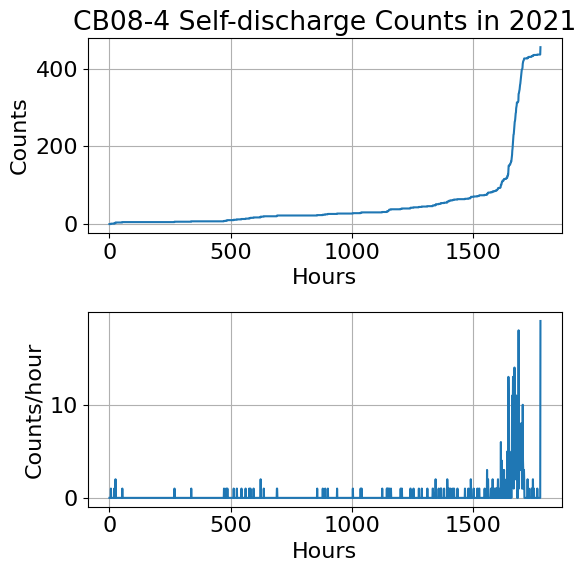

In [ ]:
# Plot
fig, ax = plt.subplots(2, 1, figsize=(6,6))
ax[0].plot(data["hrs"], data["cnt"])
ax[0].set_xlabel("Hours")
ax[0].set_ylabel("Counts")
ax[0].set_title("CB08-4 Self-discharge Counts in 2021")
ax[0].grid()
ax[1].plot(data["hrs"], data["diff"])
ax[1].set_xlabel("Hours")
ax[1].set_ylabel("Counts/hour")
ax[1].grid()
plt.tight_layout()
plt.show()

# Bayesian inference of the self-discharge counts per hour
- Assume Poisson distribution.
  - ${\rm Poi}(n|\lambda) = \frac{\lambda^n}{n!} e^{-\lambda}$
  - $E(n) = V(n) = \lambda$
- The conjugate prior function of the Poisson distribution is the Gamma distribution.
  - ${\rm Gam}(\lambda|\alpha,\beta) = \frac{\beta^\alpha}{\Gamma(\alpha)} \lambda^{\alpha-1} e^{-\beta\lambda},
    \qquad \alpha > 0, \qquad \beta > 0$
  - $E(\lambda) = \frac{\alpha}{\beta}$
  - $\ln {\rm Gam}(\lambda|\alpha,\beta) = (\alpha - 1) \ln \lambda - \beta \lambda + {\rm const.}$
- If we observe the data ${\bf N} = \{n_1, n_2, \cdots, n_T\}$, the posterior distribution is calculated to be
$$ p(\lambda|{\bf N}) \propto p({\bf N}|\lambda) p(\lambda)
= \left\{ \prod_{t=1}^T {\rm Poi}(n_t|\lambda) \right\} {\rm Gam}(\lambda|\alpha,\beta). $$
- The logarithm of the distribution is
$$ \begin{align}
\ln p(\lambda|{\bf N}) &= \sum_{t=1}^T \left[ n_t \ln \lambda - \ln n_t! - \lambda \right]
+ (\alpha -1)\ln \lambda - \beta\lambda + \alpha \ln \beta - \ln \Gamma(\alpha) + {\rm const.} \\
&= \left( \sum_{t=1}^T n_t + \alpha - 1 \right) \ln \lambda - (T + \beta)\lambda + {\rm const.}
\end{align} $$
- This formula is the same as the Gamma distribution. Therefore,
$$ p(\lambda|{\bf N}) = {\rm Gam}(\lambda|\hat{\alpha},\hat{\beta}), \qquad
\hat{\alpha} = \sum_{t=1}^T n_t + \alpha, \qquad \hat{\beta} = T+\beta. $$

- Now, we use the mean of the first 100 hours for the prior mean.
- We set the initial $\alpha$ to 1.

alpha = 1.0, beta = 20.0


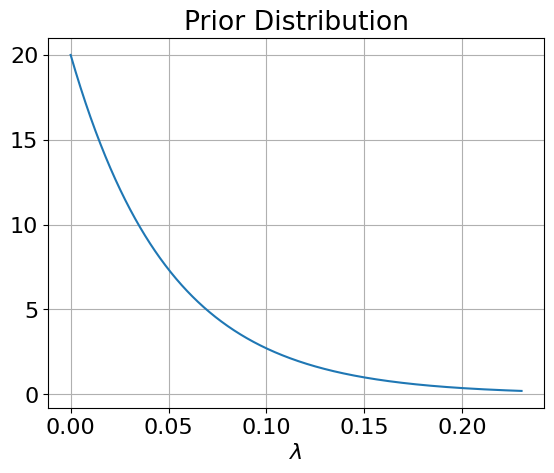

In [ ]:
# Prior distribution of lambda
hrs0 = 100
a0 = 1.
b0 = a0 / data["diff"][data["hrs"]<hrs0].mean()
prior = gamma(a0, scale=1./b0)
print(f"alpha = {a0}, beta = {b0}")

x = np.linspace(prior.ppf(0.), prior.ppf(0.99), 1000)
fig, ax = plt.subplots()
ax.plot(x, prior.pdf(x))
ax.grid()
ax.set_xlabel("$\lambda$")
ax.set_title("Prior Distribution")
plt.show()

In [ ]:
# Posterior parameters
data["a"] = data["cnt"] + a0
data["b"] = data["hrs"] + b0
display(data)

,i,time,cnt,hrs,diff,a,b
0,0,2021-06-15 18:35:51.419,0,0,0,1.0,20.0
1,1,2021-06-15 19:37:53.630,0,1,0,1.0,21.0
2,2,2021-06-15 20:37:06.631,0,2,0,1.0,22.0
3,3,2021-06-15 21:37:09.608,0,3,0,1.0,23.0
4,4,2021-06-15 22:38:10.750,0,4,0,1.0,24.0
...,...,...,...,...,...,...,...
1772,1772,2021-10-21 21:19:04.364,436,1772,0,437.0,1792.0
1773,1773,2021-10-21 22:19:05.184,436,1773,0,437.0,1793.0
1774,1774,2021-10-21 23:19:09.602,436,1774,0,437.0,1794.0
1775,1775,2021-10-22 00:19:09.844,436,1775,0,437.0,1795.0


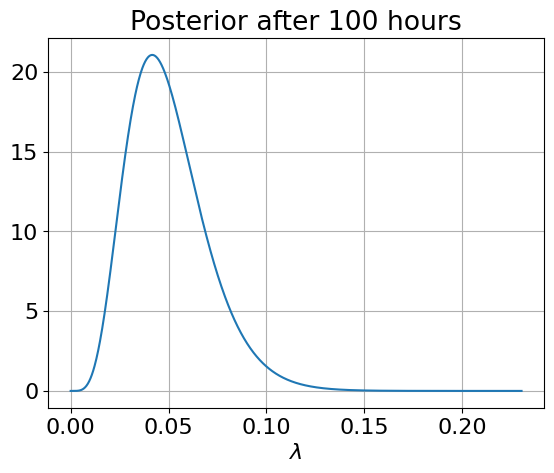

time = 100 hours, alpha = 6.0, beta = 120.0


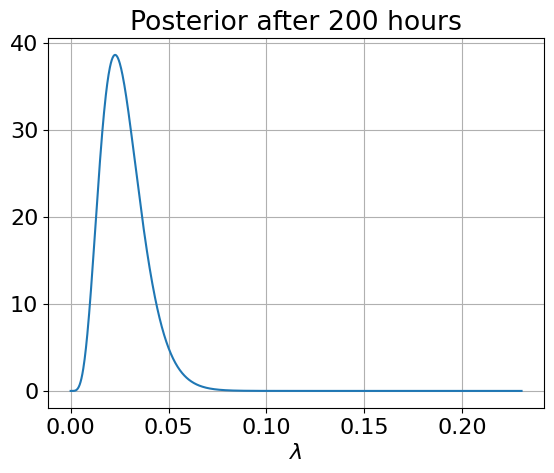

time = 200 hours, alpha = 6.0, beta = 220.0


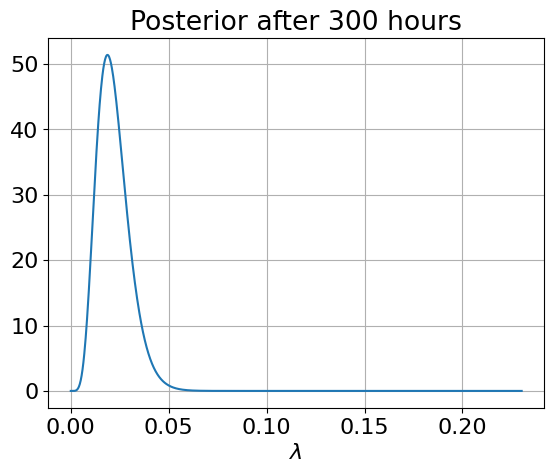

time = 300 hours, alpha = 7.0, beta = 320.0


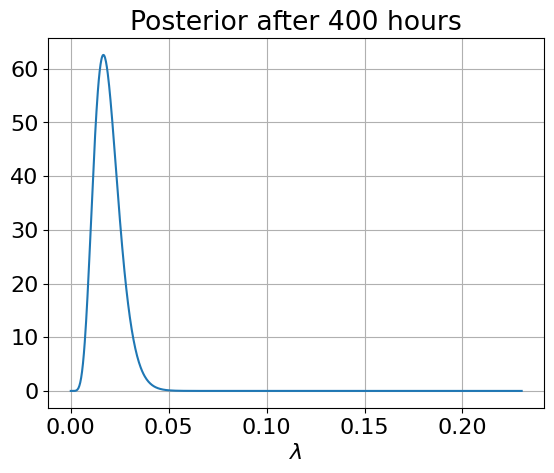

time = 400 hours, alpha = 8.0, beta = 420.0


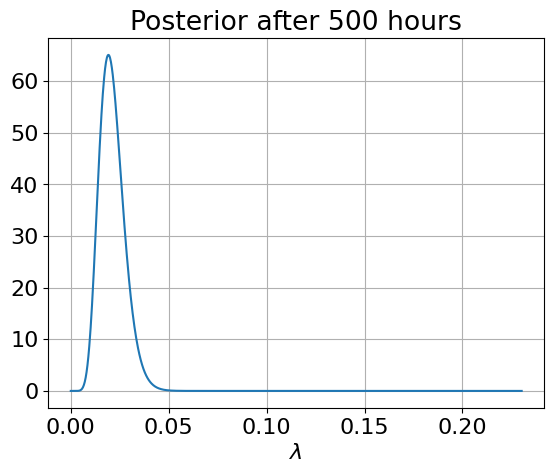

time = 500 hours, alpha = 11.0, beta = 520.0


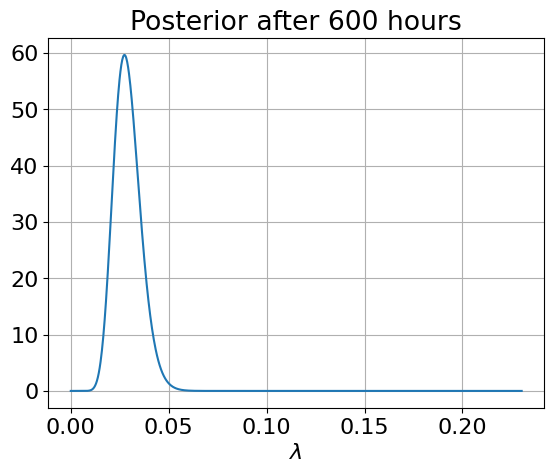

time = 600 hours, alpha = 18.0, beta = 620.0


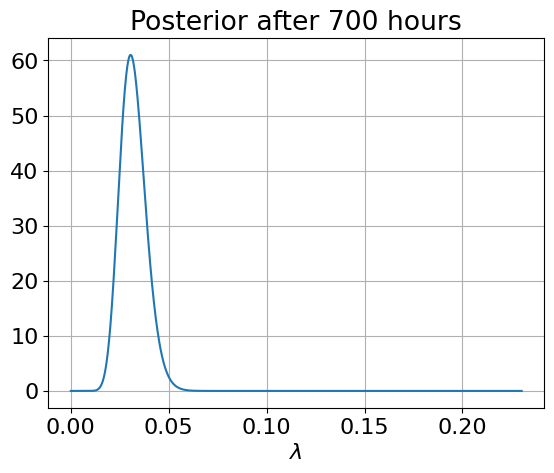

time = 700 hours, alpha = 23.0, beta = 720.0


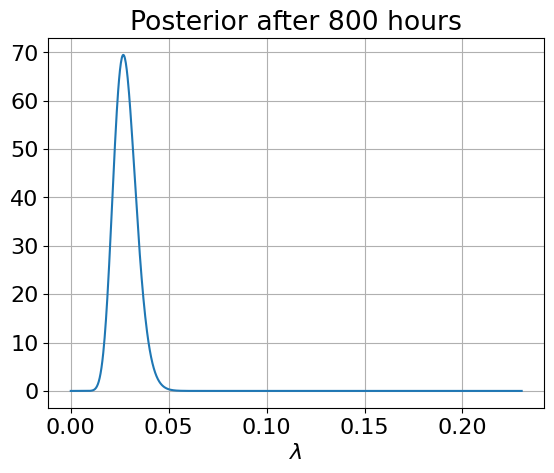

time = 800 hours, alpha = 23.0, beta = 820.0


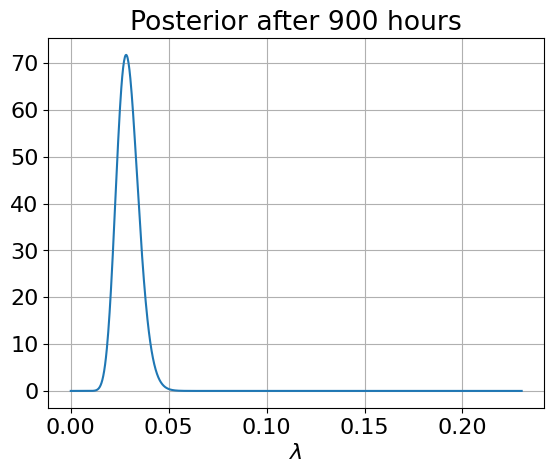

time = 900 hours, alpha = 27.0, beta = 920.0


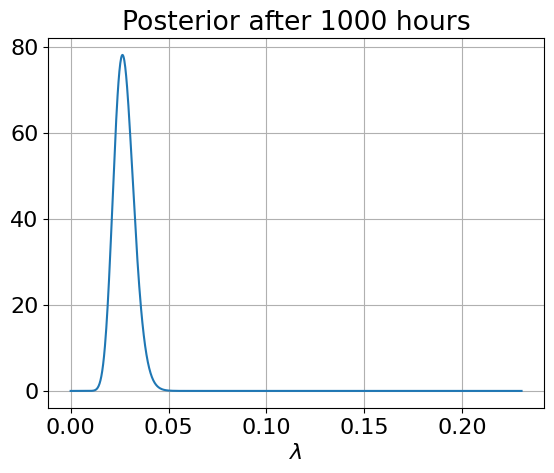

time = 1000 hours, alpha = 28.0, beta = 1020.0


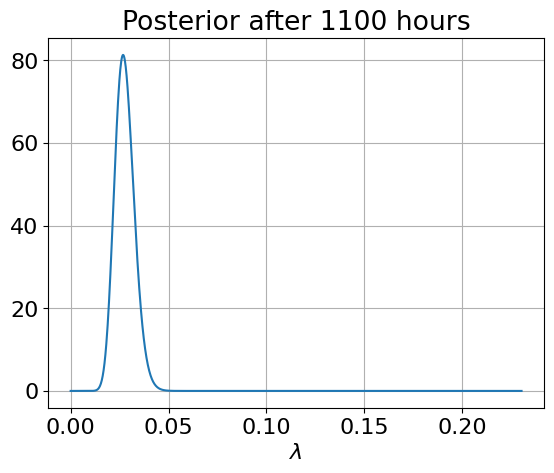

time = 1100 hours, alpha = 31.0, beta = 1120.0


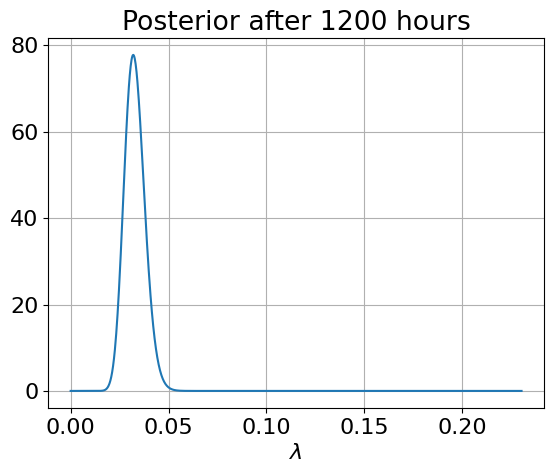

time = 1200 hours, alpha = 40.0, beta = 1220.0


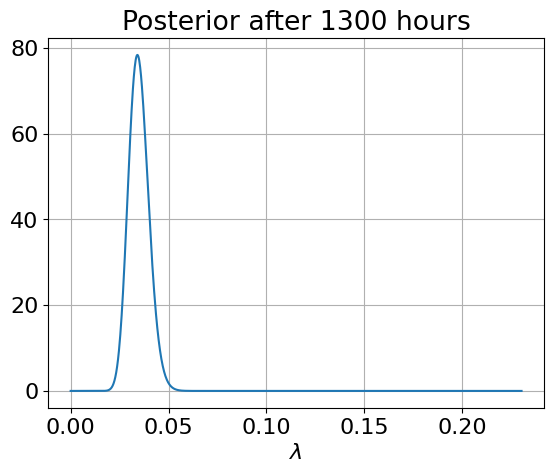

time = 1300 hours, alpha = 46.0, beta = 1320.0


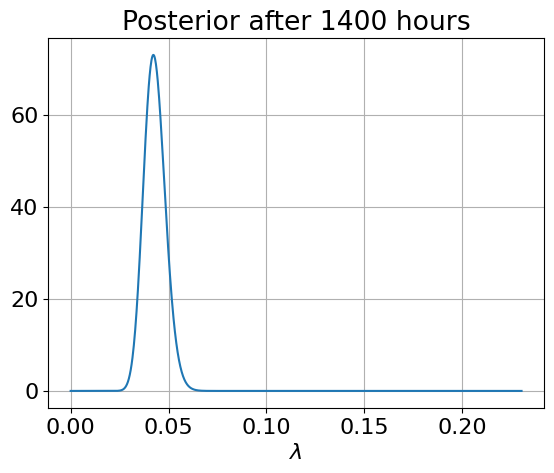

time = 1400 hours, alpha = 61.0, beta = 1420.0


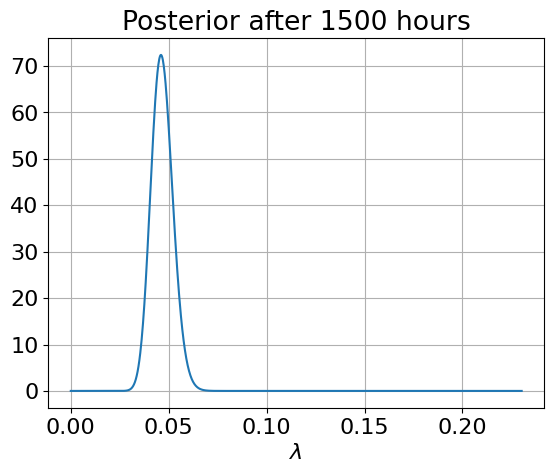

time = 1500 hours, alpha = 71.0, beta = 1520.0


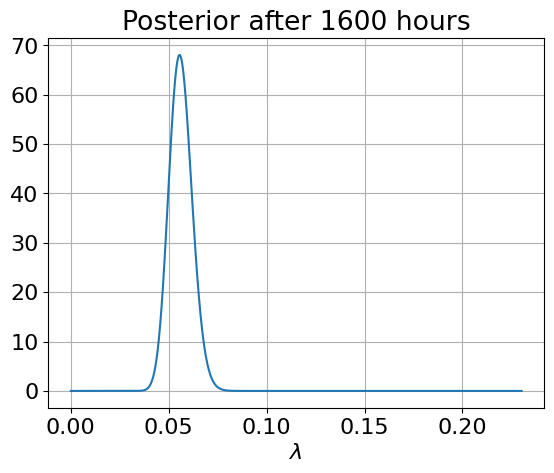

time = 1600 hours, alpha = 91.0, beta = 1620.0


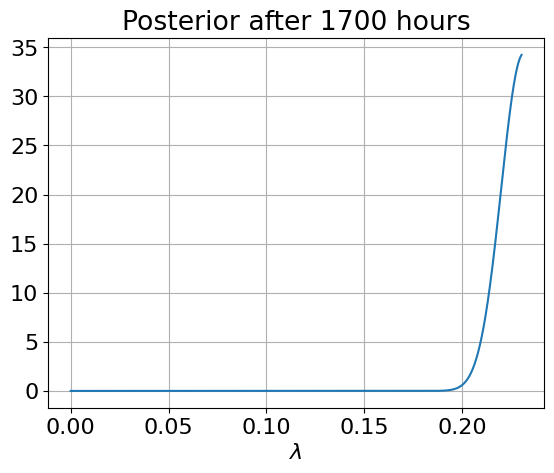

time = 1700 hours, alpha = 399.0, beta = 1720.0


In [ ]:
# Posterior distribution at every 100 hours
step = 100
for hrs in range(step, data.index.max(), step):
    param = data.loc[hrs]
    post = gamma(param["a"], scale=1./param["b"])
    fig, ax = plt.subplots()
    ax.plot(x, post.pdf(x))
    ax.grid()
    ax.set_title(f"Posterior after {hrs} hours")
    ax.set_xlabel("$\lambda$")
    plt.show()
    print(f"time = {hrs} hours, alpha = {param['a']}, beta = {param['b']}")

,i,time,cnt,hrs,diff,a,b,E
0,0,2021-06-15 18:35:51.419,0,0,0,1.0,20.0,0.050000
1,1,2021-06-15 19:37:53.630,0,1,0,1.0,21.0,0.047619
2,2,2021-06-15 20:37:06.631,0,2,0,1.0,22.0,0.045455
3,3,2021-06-15 21:37:09.608,0,3,0,1.0,23.0,0.043478
4,4,2021-06-15 22:38:10.750,0,4,0,1.0,24.0,0.041667
...,...,...,...,...,...,...,...,...
1772,1772,2021-10-21 21:19:04.364,436,1772,0,437.0,1792.0,0.243862
1773,1773,2021-10-21 22:19:05.184,436,1773,0,437.0,1793.0,0.243726
1774,1774,2021-10-21 23:19:09.602,436,1774,0,437.0,1794.0,0.243590
1775,1775,2021-10-22 00:19:09.844,436,1775,0,437.0,1795.0,0.243454


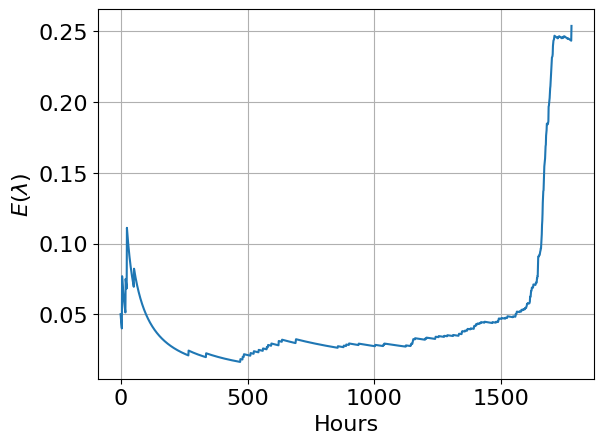

In [ ]:
# Evolution of the expectation of lambda
data["E"] = data["a"] / data["b"]
display(data)
fig, ax = plt.subplots()
ax.plot(data["hrs"], data["E"])
ax.set_xlabel("Hours")
ax.set_ylabel("$E(\lambda)$")
ax.grid()
plt.show()

,i,time,cnt,hrs,diff,a,b,E,low,high
0,0,2021-06-15 18:35:51.419,0,0,0,1.0,20.0,0.050000,0.005268,0.115129
1,1,2021-06-15 19:37:53.630,0,1,0,1.0,21.0,0.047619,0.005017,0.109647
2,2,2021-06-15 20:37:06.631,0,2,0,1.0,22.0,0.045455,0.004789,0.104663
3,3,2021-06-15 21:37:09.608,0,3,0,1.0,23.0,0.043478,0.004581,0.100112
4,4,2021-06-15 22:38:10.750,0,4,0,1.0,24.0,0.041667,0.004390,0.095941
...,...,...,...,...,...,...,...,...,...,...
1772,1772,2021-10-21 21:19:04.364,436,1772,0,437.0,1792.0,0.243862,0.229036,0.258926
1773,1773,2021-10-21 22:19:05.184,436,1773,0,437.0,1793.0,0.243726,0.228909,0.258782
1774,1774,2021-10-21 23:19:09.602,436,1774,0,437.0,1794.0,0.243590,0.228781,0.258637
1775,1775,2021-10-22 00:19:09.844,436,1775,0,437.0,1795.0,0.243454,0.228653,0.258493


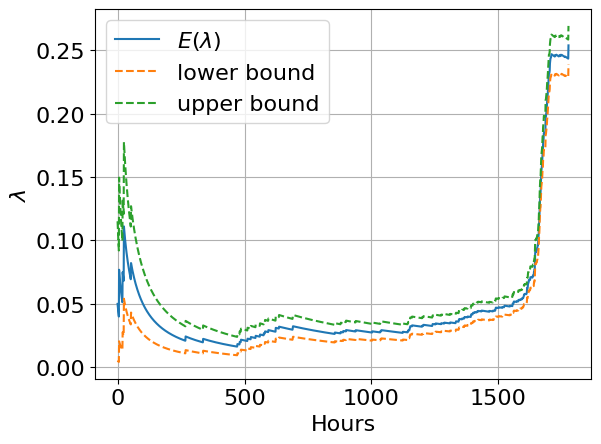

In [ ]:
# with 10% - 90% interval
low = np.empty(len(data))
high = np.empty(len(data))
for i in range(len(data)):
    post = gamma(data["a"].iloc[i], scale=1./data["b"].iloc[i])
    low[i] = post.ppf(0.1)
    high[i] = post.ppf(0.9)
data["low"] = low
data["high"] = high
display(data)
fig, ax = plt.subplots()
ax.plot(data["hrs"], data["E"], label="$E(\lambda)$")
ax.plot(data["hrs"], data["low"], '--', label="lower bound")
ax.plot(data["hrs"], data["high"], '--', label="upper bound")
ax.set_xlabel("Hours")
ax.set_ylabel("$\lambda$")
ax.grid()
ax.legend()
plt.show()

# Predicted distribution of the count
- $n_*$: predicted counts
$$ \begin{align}
p(n_*) &= \int p(n_*|\lambda)p(\lambda)d\lambda \\
&= \int {\rm Poi}(n_*|\lambda) {\rm Gam}(\lambda|\hat{\alpha},\hat{\beta}) d\lambda \\
&= \frac{\hat{\beta}^{\hat{\alpha}}}{n_*! \Gamma(\hat{\alpha})}
   \int \lambda^{n_*+\hat{\alpha}-1} e^{-(\hat{\beta}+1)\lambda} d\lambda \\
&= \frac{\hat{\beta}^{\hat{\alpha}} \Gamma(n_*+\hat{\alpha})}
        {n_*! (\hat{\beta}+1)^{n_*+\hat{\alpha}} \Gamma(\hat{\alpha})} \\
&= \frac{\Gamma(n_*+r)}{n_*! \Gamma(r)} (1-p)^r p^{n_*}
\end{align} $$
- Here, we defined $r=\hat{\alpha}$, $p=\frac{1}{\hat{\beta}+1}$.
- This distribution is called negative binomial distribution.
- $E(n_*) = \frac{pr}{1-p} = \frac{\hat{\alpha}}{\hat{\beta}}$
- $E(n_*^2) = \frac{pr(pr+1)}{(1-p)^2} = \frac{\hat{\alpha}(\hat{\alpha}+\hat{\beta}+1)}{\hat{\beta}^2}$
- $V(n_*) = E(n_*^2) - [E(n_*)]^2 = \frac{pr}{(1-p)^2} = \frac{\hat{\alpha}(\hat{\beta}+1)}{\hat{\beta}^2}$

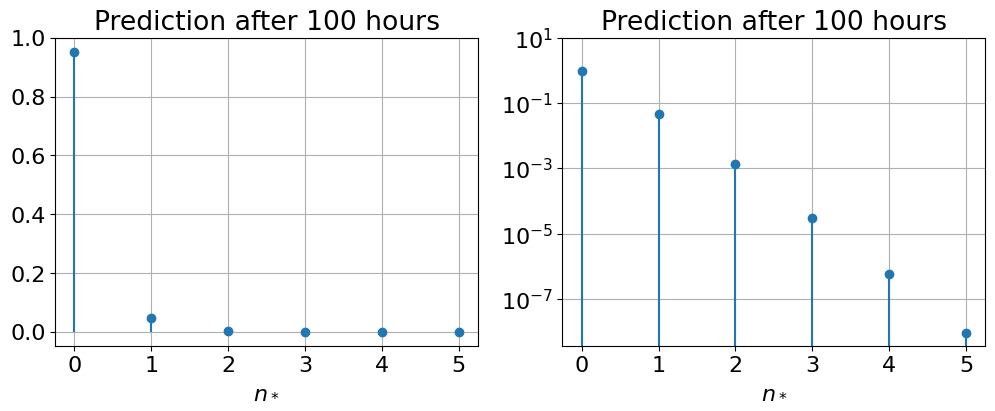

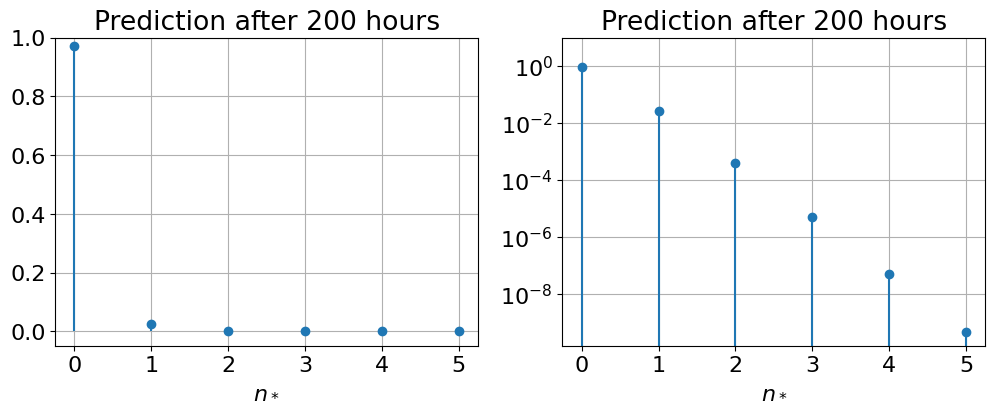

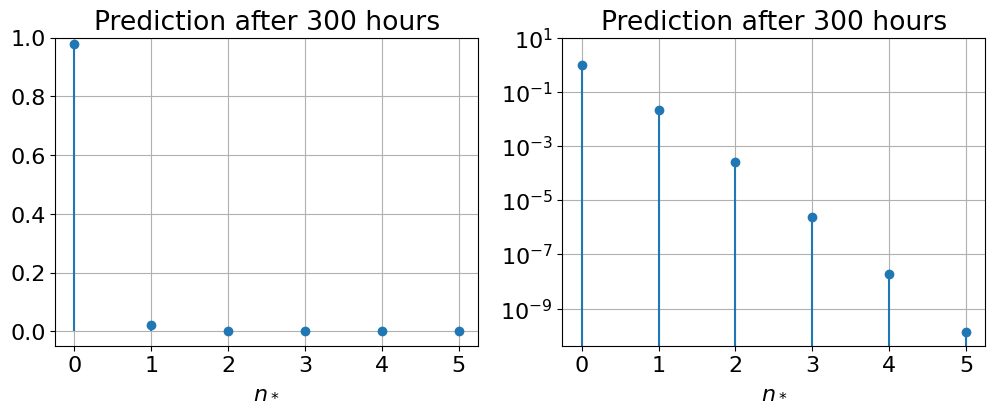

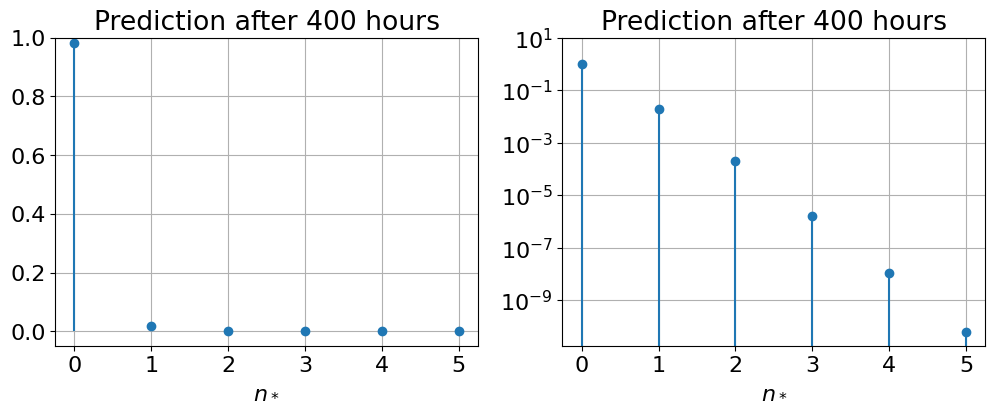

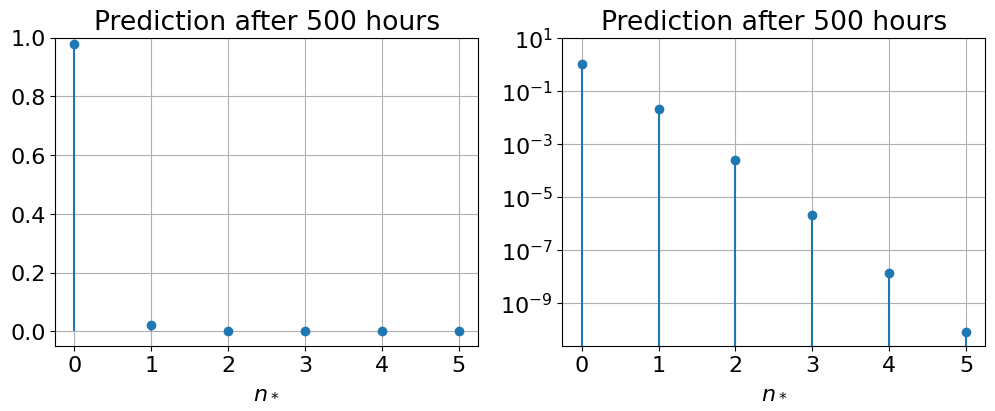

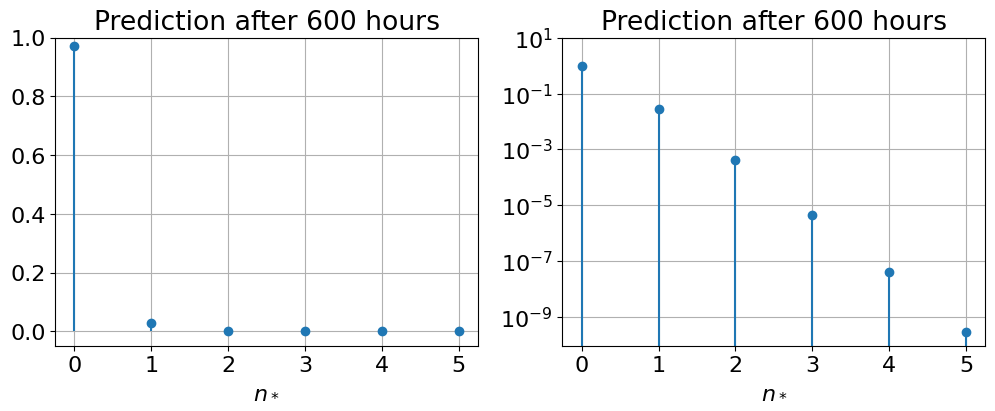

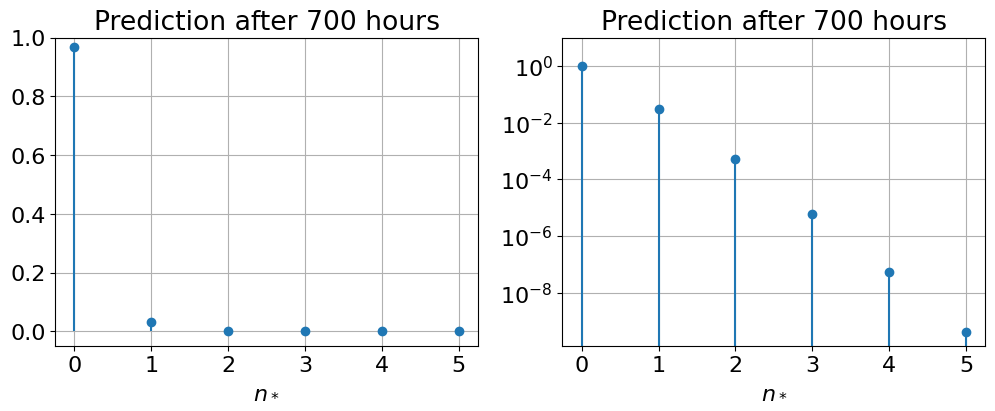

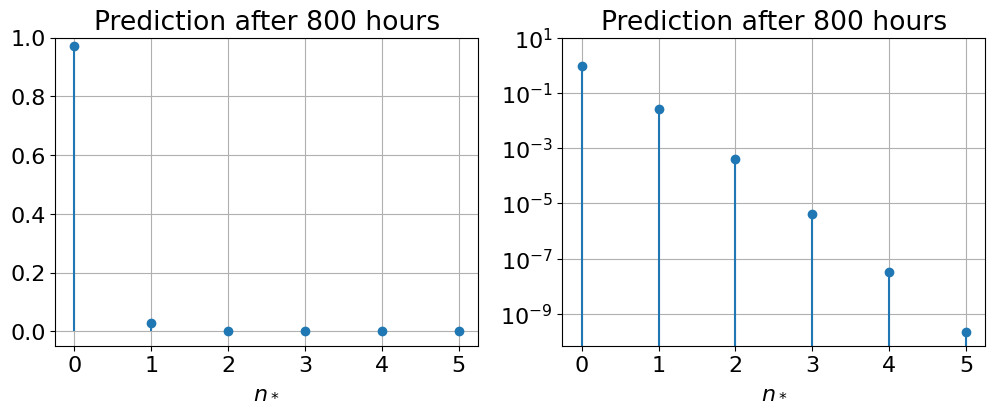

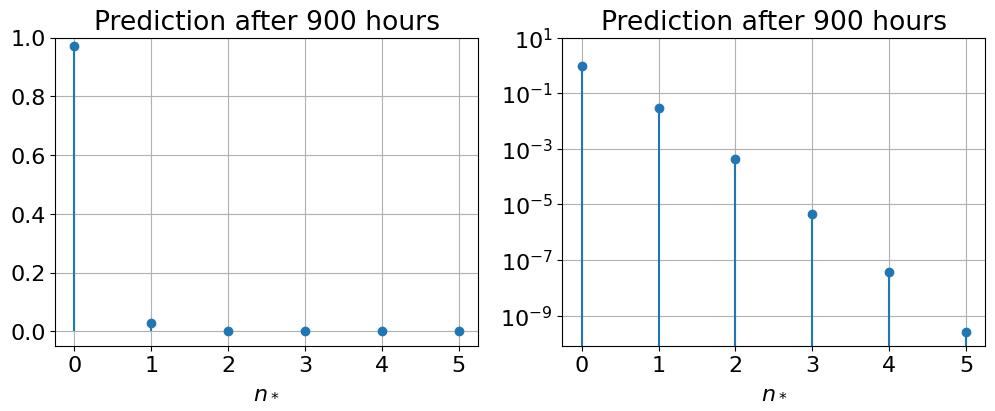

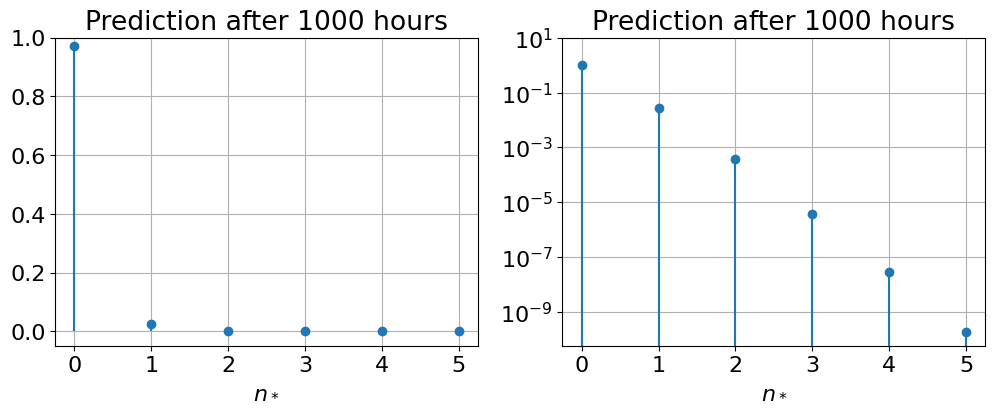

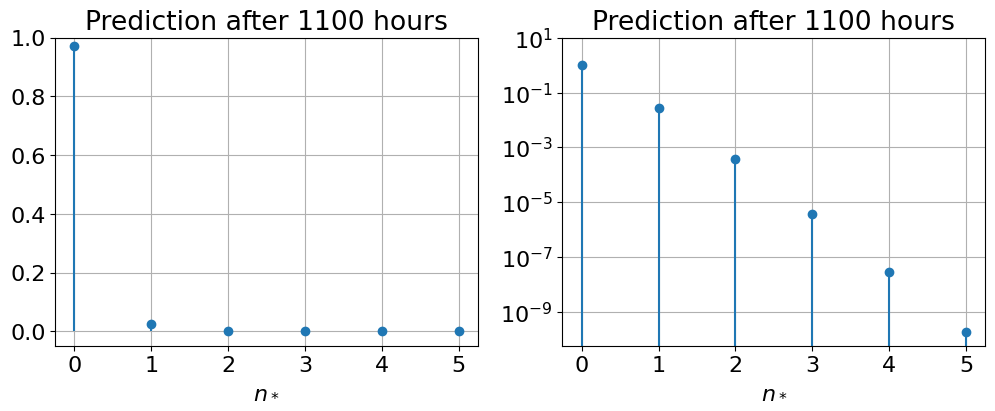

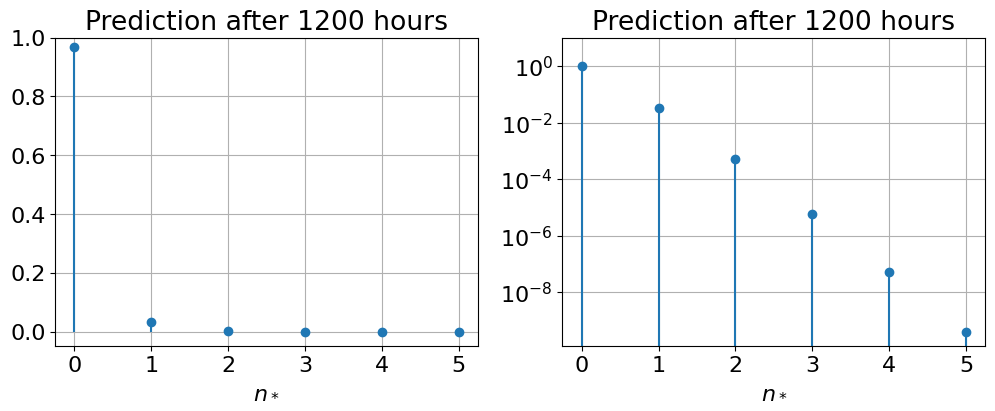

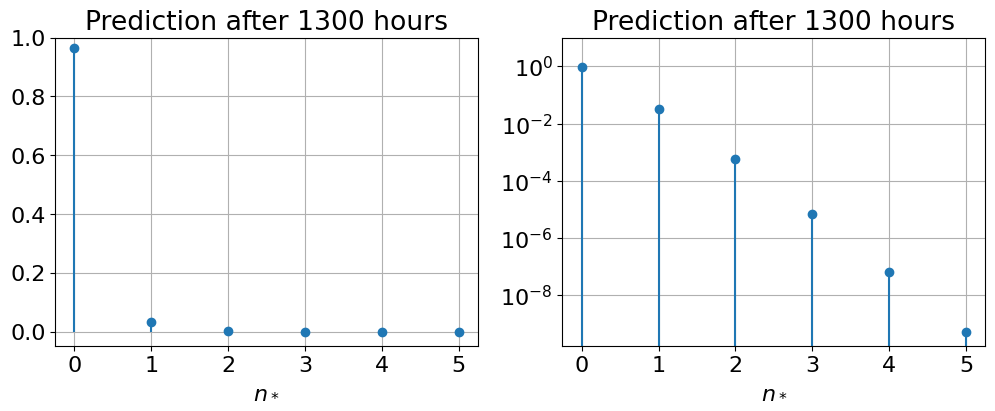

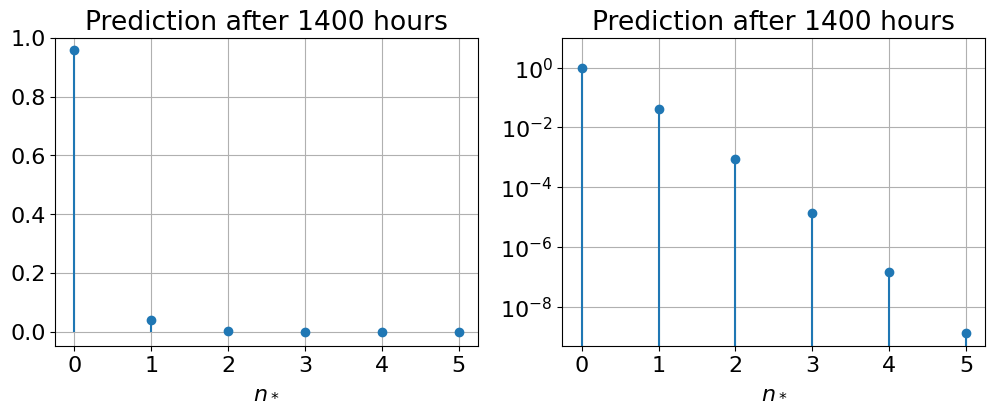

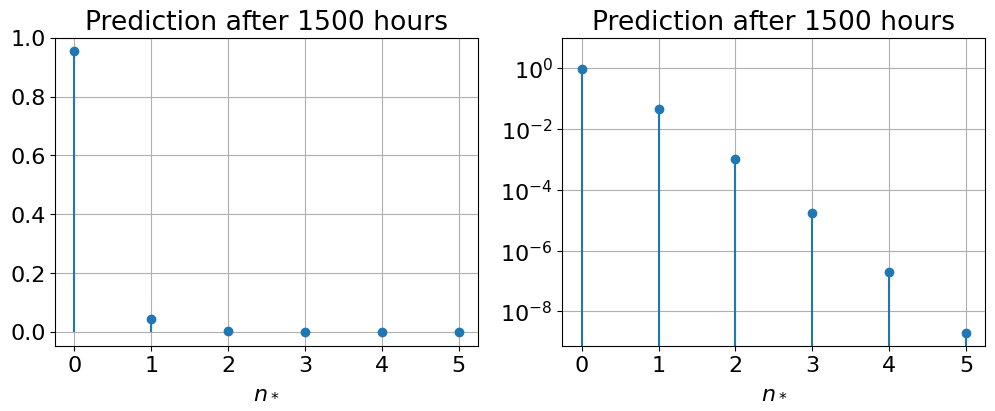

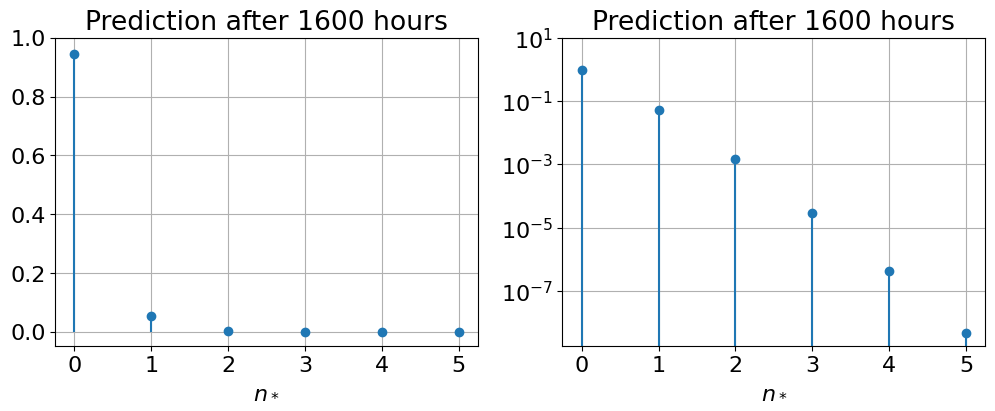

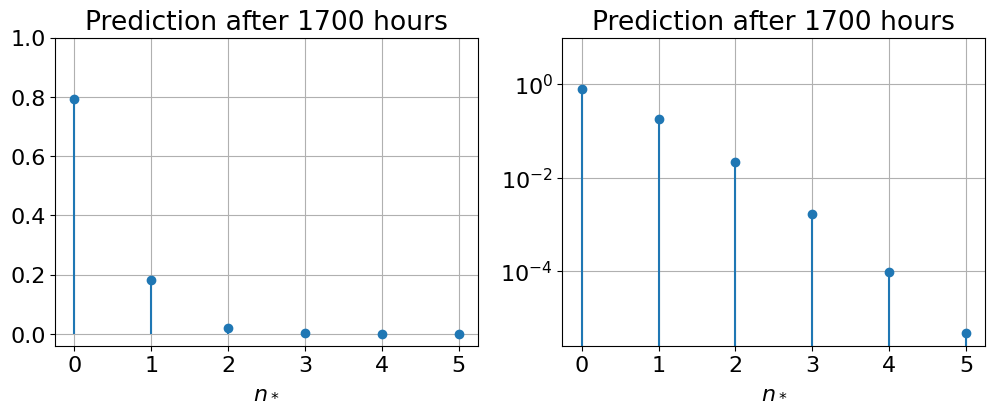

In [ ]:
# Predicted distribution at every 100 hours
step = 100
n = np.arange(0, 6, dtype=int)
for hrs in range(step, data.index.max(), step):
    param = data.loc[hrs]
    pred = nbinom(param["a"], param["b"]/(1+param["b"]))
    fig, ax = plt.subplots(1, 2, figsize=(12,4))
    for i in range(2):
        ax[i].vlines(n, 0, pred.pmf(n))
        ax[i].plot(n, pred.pmf(n), 'o')
        ax[i].grid()
        ax[i].set_title(f"Prediction after {hrs} hours")
        ax[i].set_xlabel("$n_*$")
    ax[0].set_ylim([None, 1.0])
    ax[1].set_yscale("log")
    ax[1].set_ylim([None, 10.0])
    plt.show()

# Expectation of predicted cumulative counts

In [ ]:
data["pred"] = data["hrs"]*data["E"]
data["dcnt"] = data["cnt"]-data["pred"]
display(data)

,i,time,cnt,hrs,diff,a,b,E,low,high,pred,dcnt
0,0,2021-06-15 18:35:51.419,0,0,0,1.0,20.0,0.050000,0.005268,0.115129,0.000000,0.000000
1,1,2021-06-15 19:37:53.630,0,1,0,1.0,21.0,0.047619,0.005017,0.109647,0.047619,-0.047619
2,2,2021-06-15 20:37:06.631,0,2,0,1.0,22.0,0.045455,0.004789,0.104663,0.090909,-0.090909
3,3,2021-06-15 21:37:09.608,0,3,0,1.0,23.0,0.043478,0.004581,0.100112,0.130435,-0.130435
4,4,2021-06-15 22:38:10.750,0,4,0,1.0,24.0,0.041667,0.004390,0.095941,0.166667,-0.166667
...,...,...,...,...,...,...,...,...,...,...,...,...
1772,1772,2021-10-21 21:19:04.364,436,1772,0,437.0,1792.0,0.243862,0.229036,0.258926,432.122768,3.877232
1773,1773,2021-10-21 22:19:05.184,436,1773,0,437.0,1793.0,0.243726,0.228909,0.258782,432.125488,3.874512
1774,1774,2021-10-21 23:19:09.602,436,1774,0,437.0,1794.0,0.243590,0.228781,0.258637,432.128205,3.871795
1775,1775,2021-10-22 00:19:09.844,436,1775,0,437.0,1795.0,0.243454,0.228653,0.258493,432.130919,3.869081


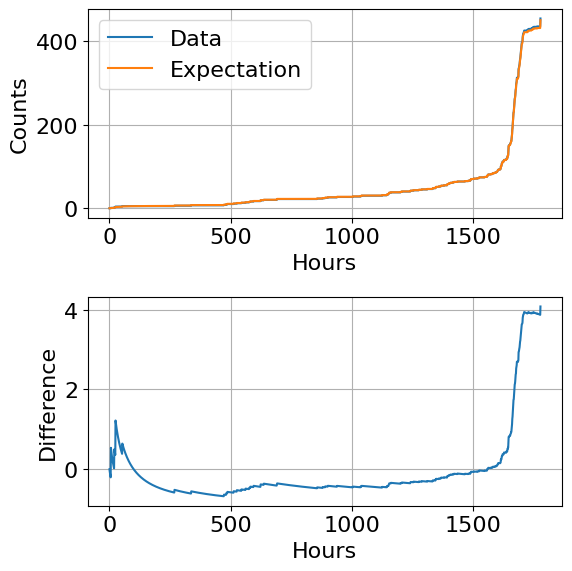

In [ ]:
# Plot
fig, ax = plt.subplots(2, 1, figsize=(6,6))
ax[0].plot(data["hrs"], data["cnt"], label="Data")
ax[0].plot(data["hrs"], data["pred"], label="Expectation")
ax[0].grid()
ax[0].legend()
ax[0].set_xlabel("Hours")
ax[0].set_ylabel("Counts")
ax[1].plot(data["hrs"], data["dcnt"])
ax[1].grid()
ax[1].set_xlabel("Hours")
ax[1].set_ylabel("Difference")
plt.tight_layout()
plt.show()

In [ ]:
display(data[(data["hrs"]>100)&(data["dcnt"]>1)])

,i,time,cnt,hrs,diff,a,b,E,low,high,pred,dcnt
1658,1658,2021-10-17 02:11:09.755,169,1658,3,170.0,1678.0,0.101311,0.091489,0.111388,167.973778,1.026222
1659,1659,2021-10-17 03:12:10.463,178,1659,9,179.0,1679.0,0.106611,0.096535,0.116942,176.867778,1.132222
1660,1660,2021-10-17 04:12:11.318,189,1660,11,190.0,1680.0,0.113095,0.102716,0.123729,187.738095,1.261905
1661,1661,2021-10-17 05:13:04.619,194,1661,5,195.0,1681.0,0.116002,0.105492,0.126768,192.679952,1.320048
1662,1662,2021-10-17 06:12:16.947,203,1662,9,204.0,1682.0,0.121284,0.110537,0.132286,201.574316,1.425684
...,...,...,...,...,...,...,...,...,...,...,...,...
1772,1772,2021-10-21 21:19:04.364,436,1772,0,437.0,1792.0,0.243862,0.229036,0.258926,432.122768,3.877232
1773,1773,2021-10-21 22:19:05.184,436,1773,0,437.0,1793.0,0.243726,0.228909,0.258782,432.125488,3.874512
1774,1774,2021-10-21 23:19:09.602,436,1774,0,437.0,1794.0,0.243590,0.228781,0.258637,432.128205,3.871795
1775,1775,2021-10-22 00:19:09.844,436,1775,0,437.0,1795.0,0.243454,0.228653,0.258493,432.130919,3.869081


- The difference of the cumulative counts exceeds 1 at 1658 hours.
- This is about 5 days before the death.

# Distribution of predicted cumulative counts
- The distribution of the sum of the probability variable $n_*$ must be calculated.
- It can be calculated by using the moment-generating function (MGF).
  - ${\rm MGF}_{X}(t) = E(e^{tX}) = \int e^{tX} p(X) dX, \qquad t\in{\mathbb R}, \qquad X$: probability variable.
  - MGF is something like a Laplace transform of a probability distribution.
  - Usually, the distribution of the sum of probability variables can be calculating by taking the convolution of these variables.
  - The Laplace transform of a convolution is a product, so the sum of probability variables can be transformed to a product.
  - ${\rm MGF}_{X+Y}(t) = {\rm MGF}_{X}(t) {\rm MGF}_{Y}(t)$
- The MGF of a negative binomial distribution is
  ${\rm MGF}_{n_*} = \left( \frac{1-p}{1-pe^t} \right)^r = \left( \frac{\hat{\beta}}{\hat{\beta}+1-e^t} \right)^{\hat{\alpha}}$.
- The MGF of the sum of the negative binomial distribution is
  ${\rm MGF}_{T n_*} = \left( \frac{1-p}{1-pe^t} \right)^{Tr} = \left( \frac{\hat{\beta}}{\hat{\beta}+1-e^t} \right)^{T\hat{\alpha}}$.
- Therefore, the distribution of predicted cumulative counts is also a negative binomial distribution.
  $r=T\hat{\alpha}$, $p=\frac{1}{\hat{\beta}+1}$

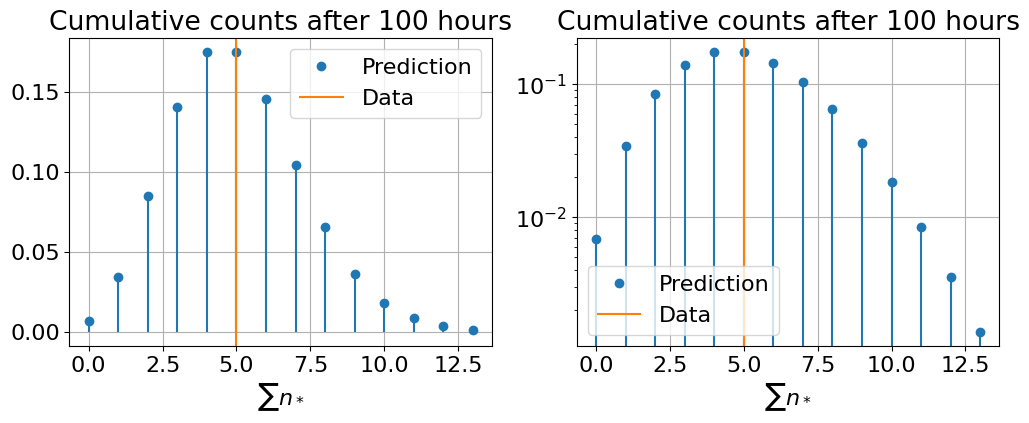

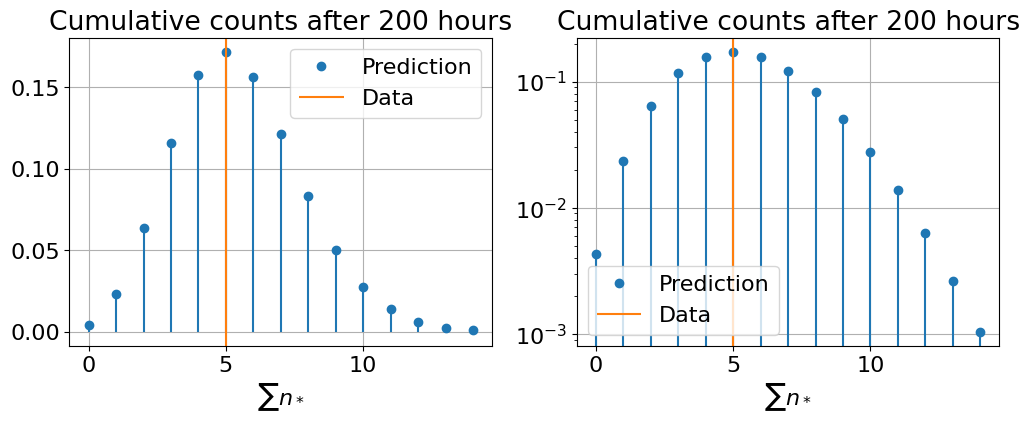

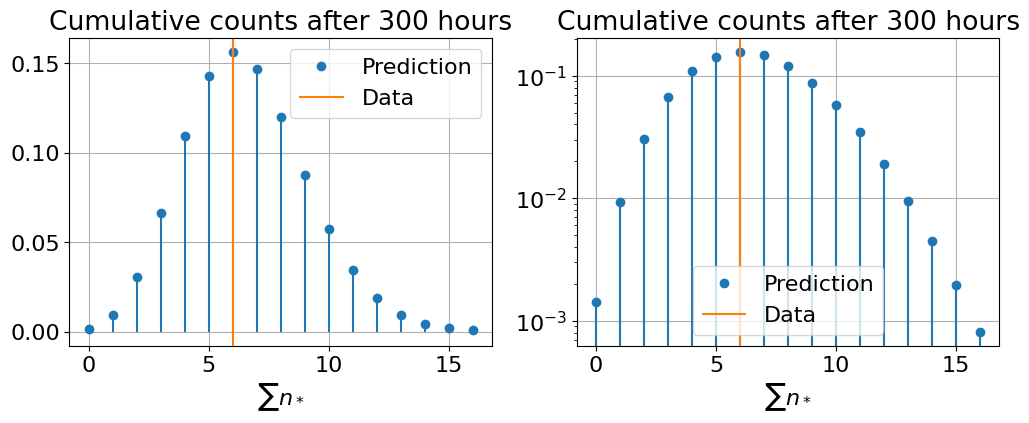

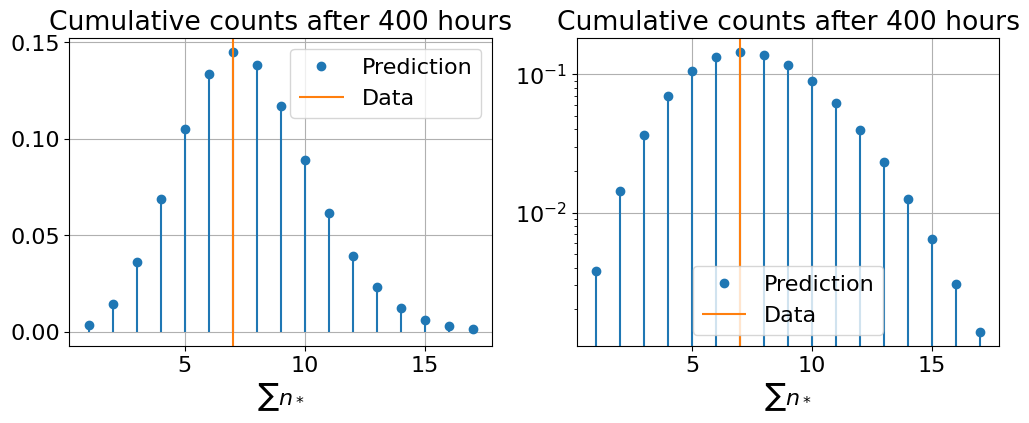

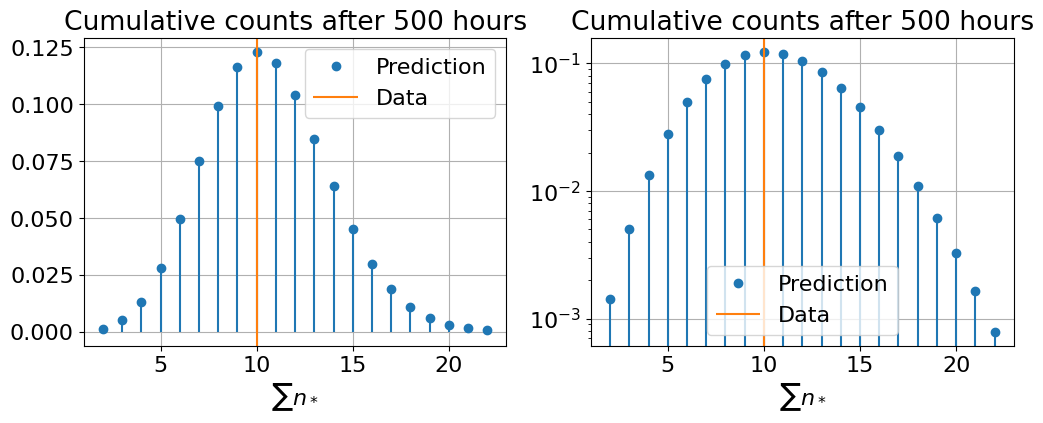

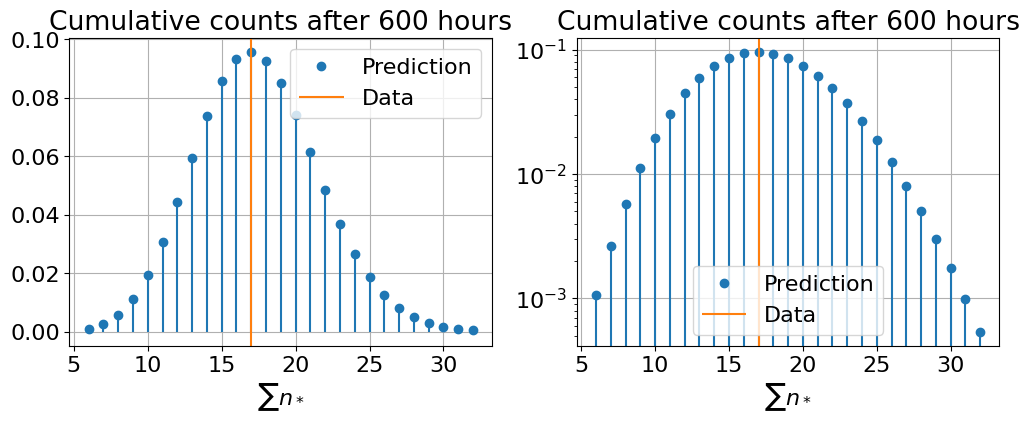

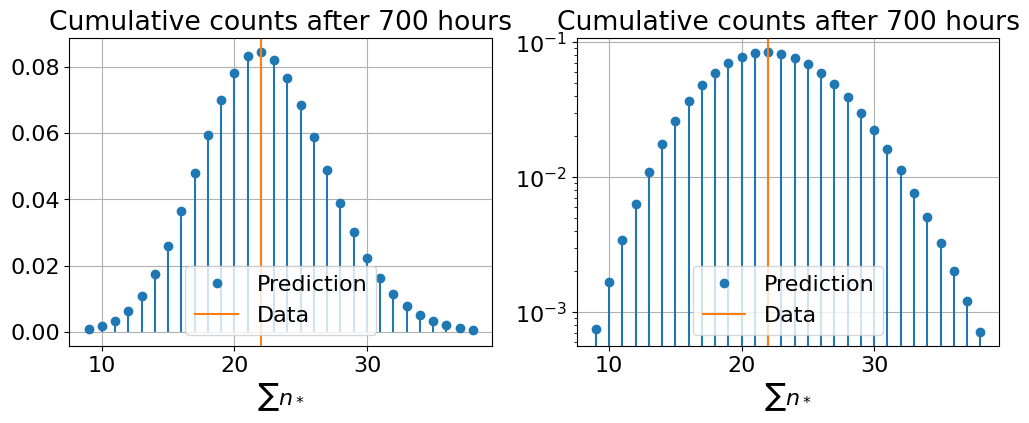

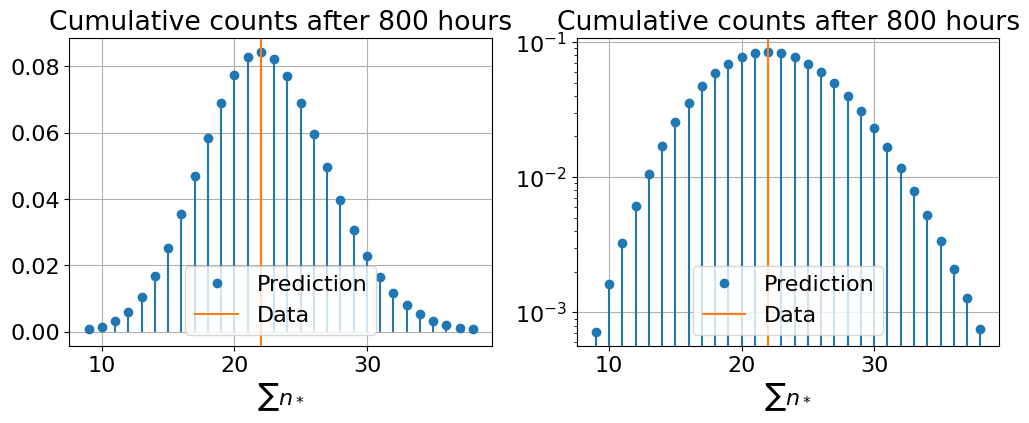

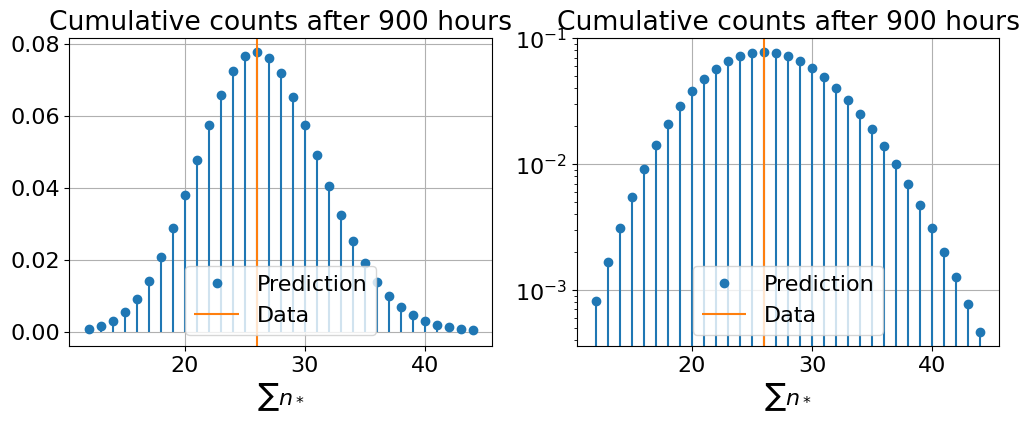

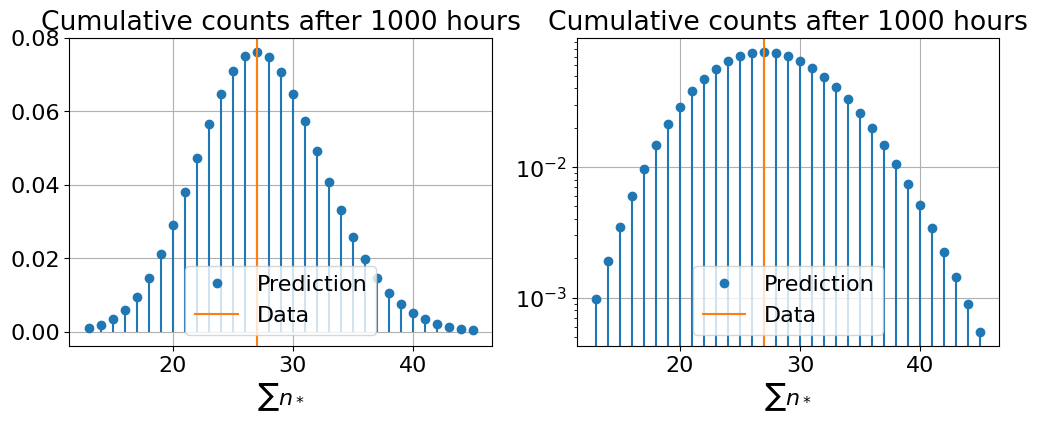

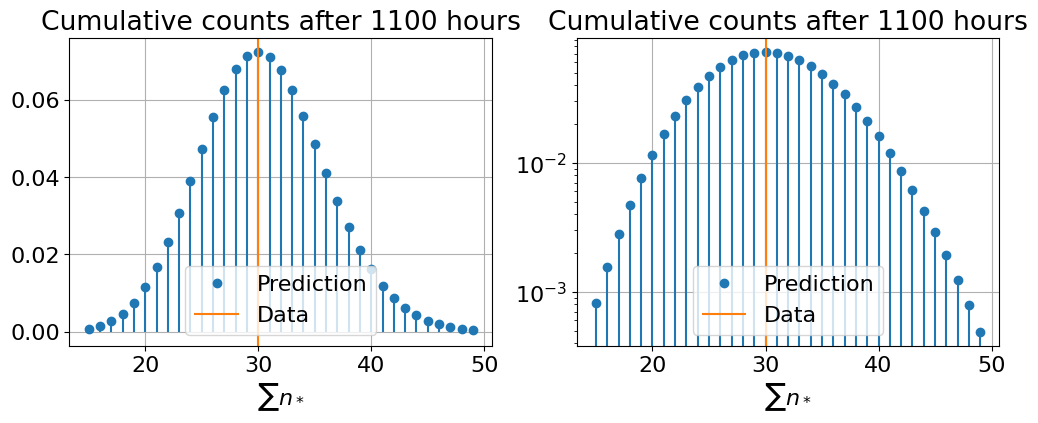

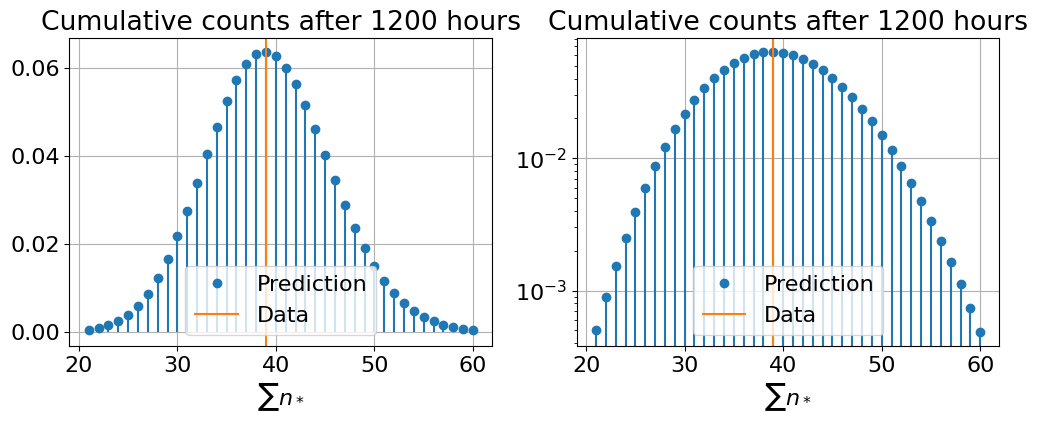

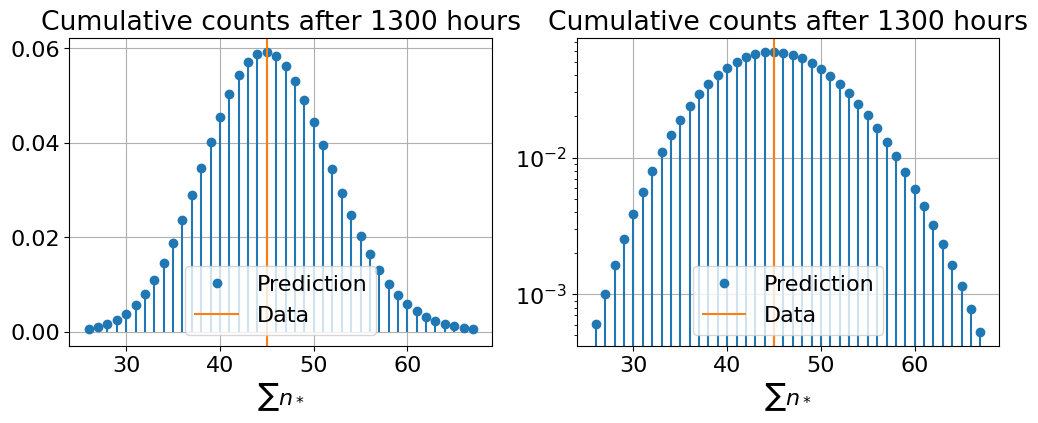

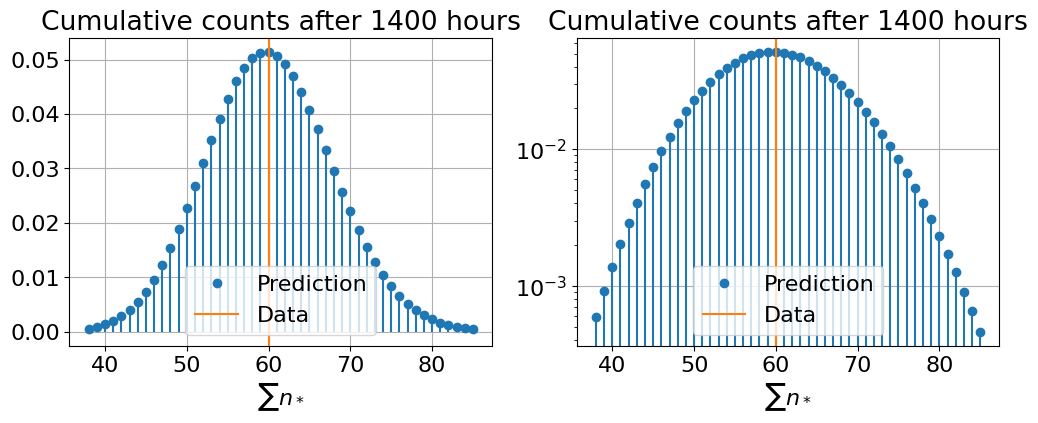

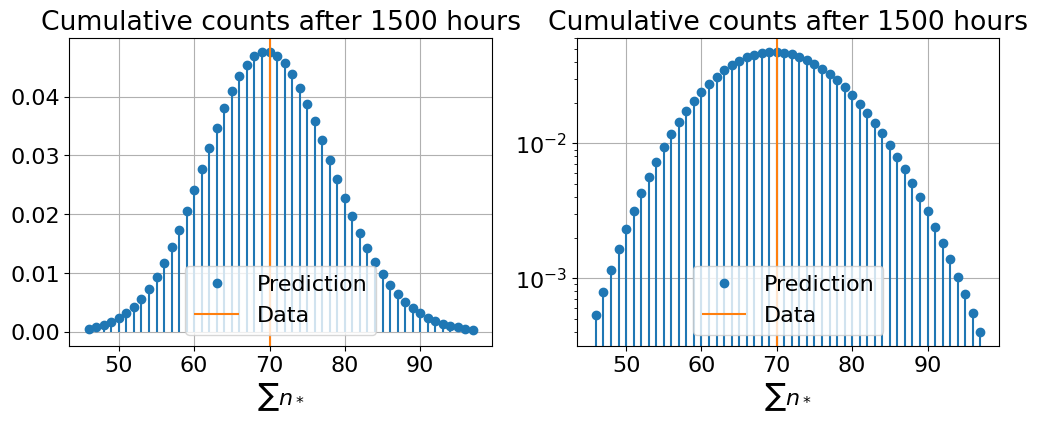

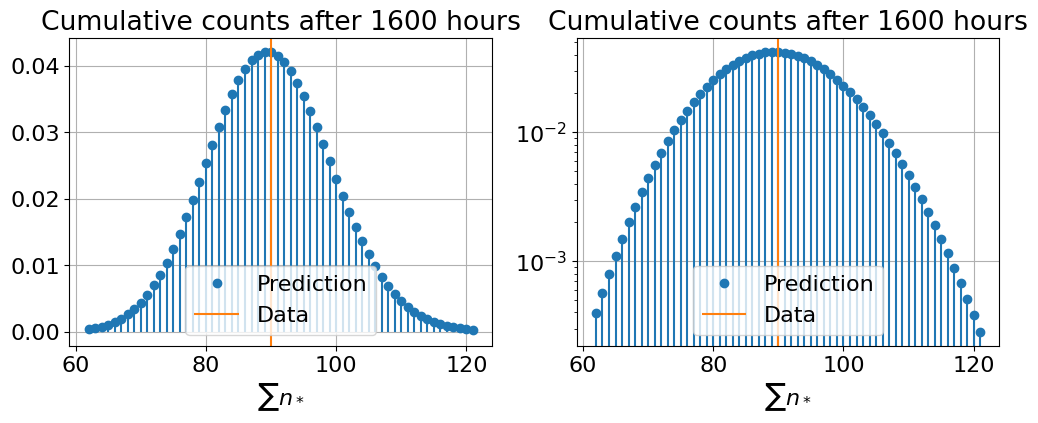

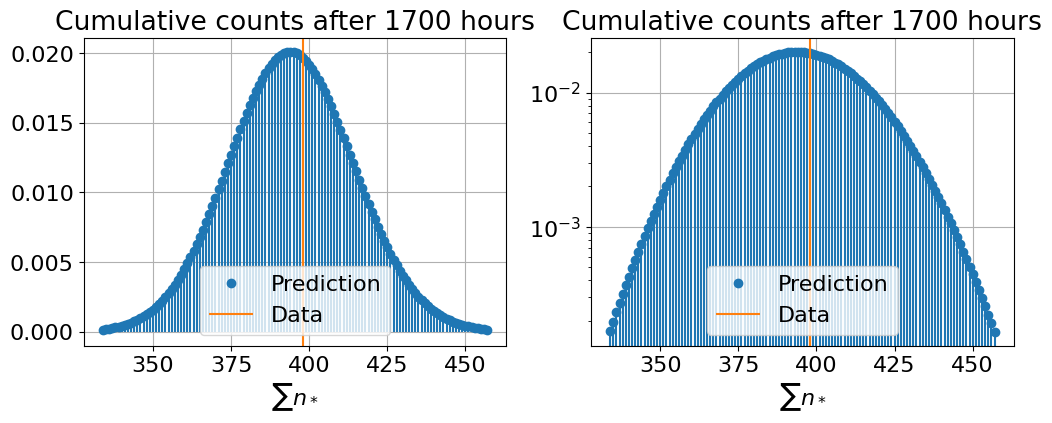

In [ ]:
# Distribution of the predicted cumulative counts at every 100 hours
step = 100
for hrs in range(step, data.index.max(), step):
    param = data.loc[hrs]
    pred = nbinom(param["a"]*hrs, param["b"]/(1+param["b"]))
    nmin = pred.ppf(0.001)
    nmax = pred.ppf(0.999)
    n = np.arange(nmin, nmax+1, dtype=int)
    fig, ax = plt.subplots(1, 2, figsize=(12,4))
    for i in range(2):
        ax[i].vlines(n, 0, pred.pmf(n))
        ax[i].plot(n, pred.pmf(n), 'o', label="Prediction")
        if i == 1:
            ax[1].set_yscale("log")
        ylim = ax[i].get_ylim()
        ax[i].vlines(param["cnt"], ylim[0], ylim[1], "C1", label="Data")
        ax[i].set_ylim(ylim)
        ax[i].grid()
        ax[i].set_title(f"Cumulative counts after {hrs} hours")
        ax[i].set_xlabel("$\sum n_*$")
        ax[i].legend()
    plt.show()

,i,time,cnt,hrs,diff,a,b,E,low,high,pred,dcnt,low2,high2
0,0,2021-06-15 18:35:51.419,0,0,0,1.0,20.0,0.050000,0.005268,0.115129,0.000000,0.000000,NaN,NaN
1,1,2021-06-15 19:37:53.630,0,1,0,1.0,21.0,0.047619,0.005017,0.109647,0.047619,-0.047619,0.0,0.0
2,2,2021-06-15 20:37:06.631,0,2,0,1.0,22.0,0.045455,0.004789,0.104663,0.090909,-0.090909,0.0,0.0
3,3,2021-06-15 21:37:09.608,0,3,0,1.0,23.0,0.043478,0.004581,0.100112,0.130435,-0.130435,0.0,1.0
4,4,2021-06-15 22:38:10.750,0,4,0,1.0,24.0,0.041667,0.004390,0.095941,0.166667,-0.166667,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1772,1772,2021-10-21 21:19:04.364,436,1772,0,437.0,1792.0,0.243862,0.229036,0.258926,432.122768,3.877232,406.0,459.0
1773,1773,2021-10-21 22:19:05.184,436,1773,0,437.0,1793.0,0.243726,0.228909,0.258782,432.125488,3.874512,406.0,459.0
1774,1774,2021-10-21 23:19:09.602,436,1774,0,437.0,1794.0,0.243590,0.228781,0.258637,432.128205,3.871795,406.0,459.0
1775,1775,2021-10-22 00:19:09.844,436,1775,0,437.0,1795.0,0.243454,0.228653,0.258493,432.130919,3.869081,406.0,459.0


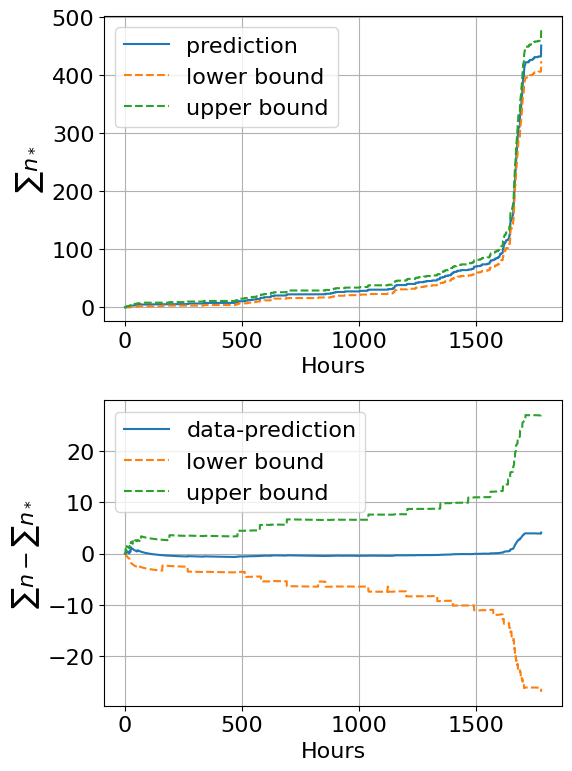

In [ ]:
# 10% - 90% interval
low = np.empty(len(data))
high = np.empty(len(data))
for i in range(len(data)):
    pred = nbinom(data["a"].iloc[i]*i, data["b"].iloc[i]/(1+data["b"].iloc[i]))
    low[i] = pred.ppf(0.1)
    high[i] = pred.ppf(0.9)
data["low2"] = low
data["high2"] = high
display(data)
fig, ax = plt.subplots(2, 1, figsize=(6, 8))
ax[0].plot(data["hrs"], data["pred"], label="prediction")
ax[0].plot(data["hrs"], data["low2"], '--', label="lower bound")
ax[0].plot(data["hrs"], data["high2"], '--', label="upper bound")
ax[0].set_xlabel("Hours")
ax[0].set_ylabel("$\sum n_*$")
ax[0].grid()
ax[0].legend()
ax[1].plot(data["hrs"], data["cnt"]-data["pred"], label="data-prediction")
ax[1].plot(data["hrs"], data["low2"]-data["pred"], '--', label="lower bound")
ax[1].plot(data["hrs"], data["high2"]-data["pred"], '--', label="upper bound")
ax[1].set_xlabel("Hours")
ax[1].set_ylabel("$\sum n - \sum n_*$")
ax[1].grid()
ax[1].legend()
fig.tight_layout()
plt.show()

- The data is well within the predicted distribution.
- We need to compare the data with the past distribution (24 hours before etc.).

,i,time,cnt,hrs,diff,a,b,E,low,high,pred,dcnt,low2,high2,pred3,low3,high3
0,0,2021-06-15 18:35:51.419,0,0,0,1.0,20.0,0.050000,0.005268,0.115129,0.000000,0.000000,NaN,NaN,0.000000,0.0,0.0
1,1,2021-06-15 19:37:53.630,0,1,0,1.0,21.0,0.047619,0.005017,0.109647,0.047619,-0.047619,0.0,0.0,0.000000,0.0,0.0
2,2,2021-06-15 20:37:06.631,0,2,0,1.0,22.0,0.045455,0.004789,0.104663,0.090909,-0.090909,0.0,0.0,0.000000,0.0,0.0
3,3,2021-06-15 21:37:09.608,0,3,0,1.0,23.0,0.043478,0.004581,0.100112,0.130435,-0.130435,0.0,1.0,0.000000,0.0,0.0
4,4,2021-06-15 22:38:10.750,0,4,0,1.0,24.0,0.041667,0.004390,0.095941,0.166667,-0.166667,0.0,1.0,0.000000,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1772,1772,2021-10-21 21:19:04.364,436,1772,0,437.0,1792.0,0.243862,0.229036,0.258926,432.122768,3.877232,406.0,459.0,435.984163,402.0,471.0
1773,1773,2021-10-21 22:19:05.184,436,1773,0,437.0,1793.0,0.243726,0.228909,0.258782,432.125488,3.874512,406.0,459.0,436.985868,403.0,472.0
1774,1774,2021-10-21 23:19:09.602,436,1774,0,437.0,1794.0,0.243590,0.228781,0.258637,432.128205,3.871795,406.0,459.0,436.985311,403.0,472.0
1775,1775,2021-10-22 00:19:09.844,436,1775,0,437.0,1795.0,0.243454,0.228653,0.258493,432.130919,3.869081,406.0,459.0,436.984754,403.0,472.0


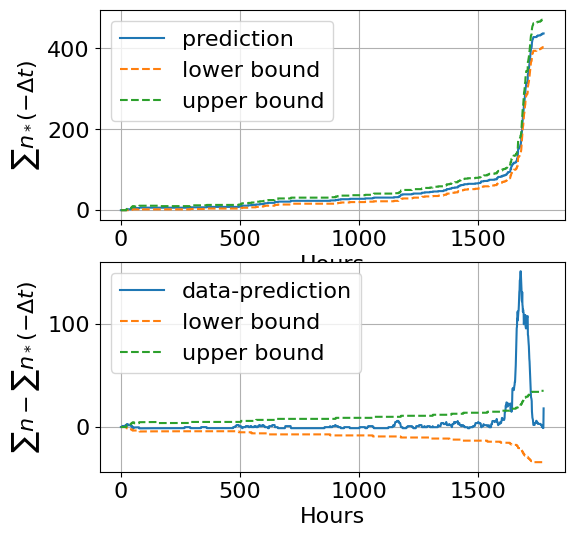

In [ ]:
# Prediction of the cumulative counts from the data 24 hours before
thre = 0.05
deltat = 24
expect = np.zeros(len(data))
low = np.zeros(len(data))
high = np.zeros(len(data))
for i in range(deltat, len(data)):
    param = data.iloc[i-deltat]
    pred = nbinom(param["a"]*i, param["b"]/(1+param["b"]))
    expect[i] = pred.mean()
    low[i] = pred.ppf(thre)
    high[i] = pred.ppf(1.-thre)
data["pred3"] = expect
data["low3"] = low
data["high3"] = high
display(data)
fig, ax = plt.subplots(2, 1, figsize=(6, 6))
ax[0].plot(data["hrs"], data["pred3"], label="prediction")
ax[0].plot(data["hrs"], data["low3"], '--', label="lower bound")
ax[0].plot(data["hrs"], data["high3"], '--', label="upper bound")
ax[0].set_xlabel("Hours")
ax[0].set_ylabel("$\sum n_*(-\Delta t)$")
ax[0].grid()
ax[0].legend()
ax[1].plot(data["hrs"], data["cnt"]-data["pred3"], label="data-prediction")
ax[1].plot(data["hrs"], data["low3"]-data["pred3"], '--', label="lower bound")
ax[1].plot(data["hrs"], data["high3"]-data["pred3"], '--', label="upper bound")
ax[1].set_xlabel("Hours")
ax[1].set_ylabel("$\sum n - \sum n_*(-\Delta t)$")
ax[1].grid()
ax[1].legend()
plt.show()

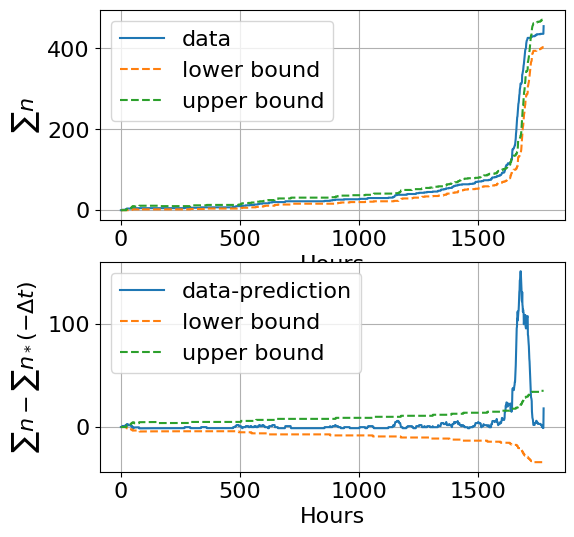

In [ ]:
# Prediction of the cumulative counts
fig, ax = plt.subplots(2, 1, figsize=(6, 6))
ax[0].plot(data["hrs"], data["cnt"], label="data")
ax[0].plot(data["hrs"], data["low3"], '--', label="lower bound")
ax[0].plot(data["hrs"], data["high3"], '--', label="upper bound")
ax[0].set_xlabel("Hours")
ax[0].set_ylabel("$\sum n$")
ax[0].grid()
ax[0].legend()
ax[1].plot(data["hrs"], data["cnt"]-data["pred3"], label="data-prediction")
ax[1].plot(data["hrs"], data["low3"]-data["pred3"], '--', label="lower bound")
ax[1].plot(data["hrs"], data["high3"]-data["pred3"], '--', label="upper bound")
ax[1].set_xlabel("Hours")
ax[1].set_ylabel("$\sum n - \sum n_*(-\Delta t)$")
ax[1].grid()
ax[1].legend()
plt.show()

In [ ]:
display(data[(data["hrs"]>100)&(data["cnt"]>data["high3"])])

,i,time,cnt,hrs,diff,a,b,E,low,high,pred,dcnt,low2,high2,pred3,low3,high3
1616,1616,2021-10-15 08:06:22.760,104,1616,3,105.0,1636.0,0.064181,0.056296,0.072327,103.716381,0.283619,91.0,117.0,87.215881,72.0,103.0
1617,1617,2021-10-15 09:07:03.002,108,1617,4,109.0,1637.0,0.066585,0.058554,0.074878,107.668296,0.331704,94.0,121.0,87.215747,72.0,103.0
1618,1618,2021-10-15 10:07:07.835,108,1618,0,109.0,1638.0,0.066545,0.058518,0.074832,107.669109,0.330891,94.0,121.0,88.218092,73.0,104.0
1619,1619,2021-10-15 11:07:07.130,109,1619,1,110.0,1639.0,0.067114,0.059055,0.075434,108.657718,0.342282,95.0,122.0,88.217957,73.0,104.0
1620,1620,2021-10-15 12:07:01.557,112,1620,3,113.0,1640.0,0.068902,0.060737,0.077329,111.621951,0.378049,98.0,125.0,88.217822,73.0,104.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1717,1717,2021-10-19 14:18:04.869,426,1717,0,427.0,1737.0,0.245826,0.230709,0.261190,422.083477,3.916523,396.0,449.0,362.845301,332.0,394.0
1718,1718,2021-10-19 15:18:06.833,426,1718,0,427.0,1738.0,0.245685,0.230576,0.261040,422.086306,3.913694,396.0,449.0,368.858810,338.0,401.0
1719,1719,2021-10-19 16:18:11.356,426,1719,0,427.0,1739.0,0.245543,0.230444,0.260889,422.089132,3.910868,396.0,449.0,373.869971,342.0,406.0
1720,1720,2021-10-19 17:18:04.170,426,1720,0,427.0,1740.0,0.245402,0.230311,0.260740,422.091954,3.908046,396.0,449.0,381.888112,350.0,414.0


- We set the upper limit to the 95% limit of the distribution 24 hours before.
- The difference of the cumulative counts exceeds this limit at 1616 hours.
- This is about 7 days before the death.

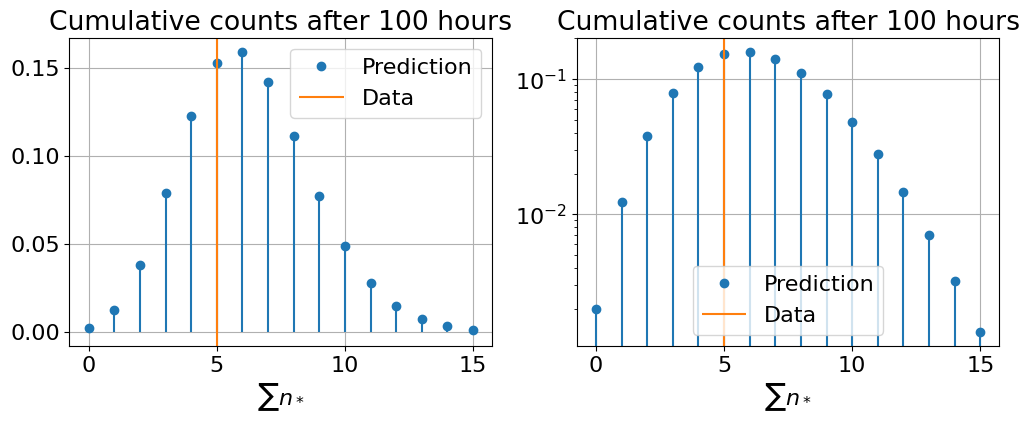

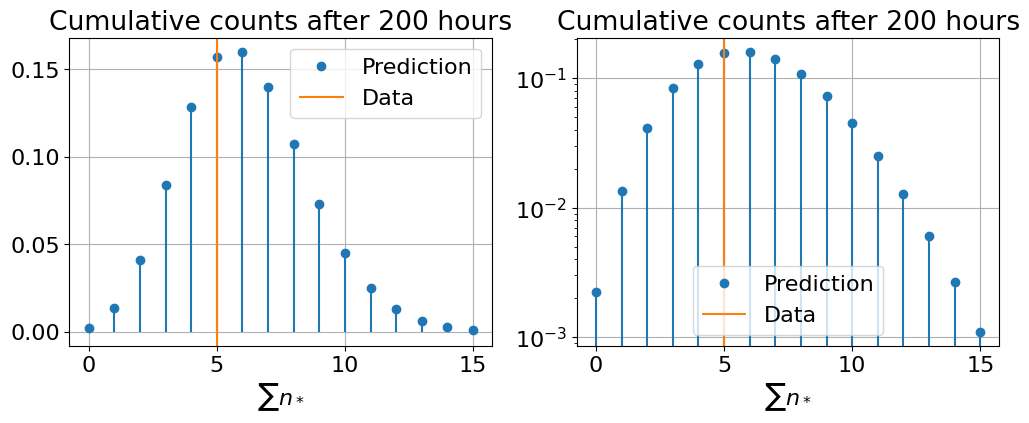

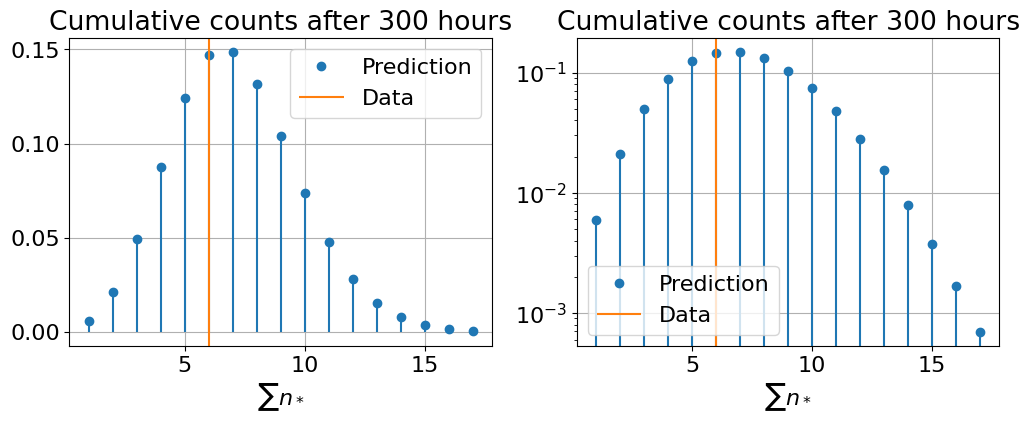

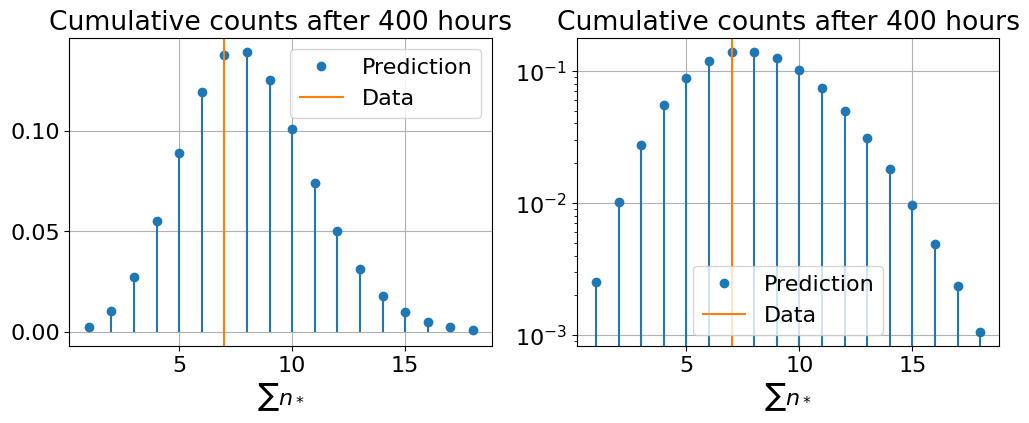

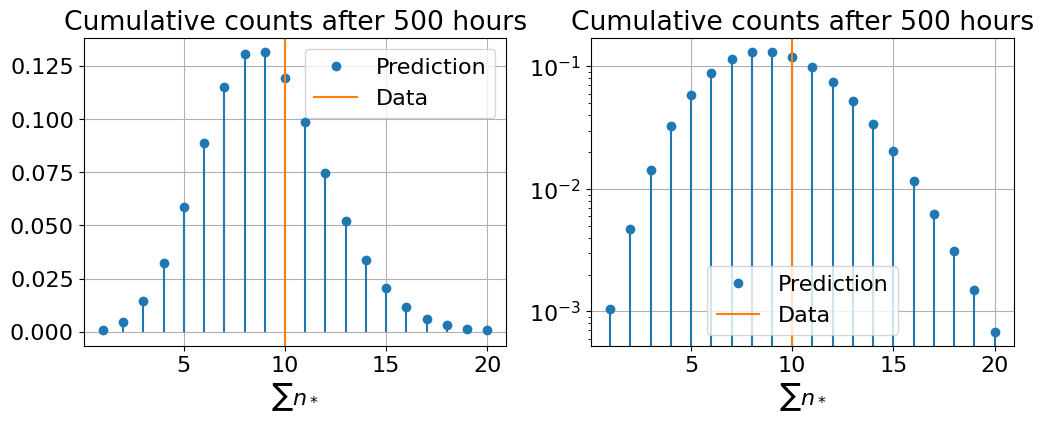

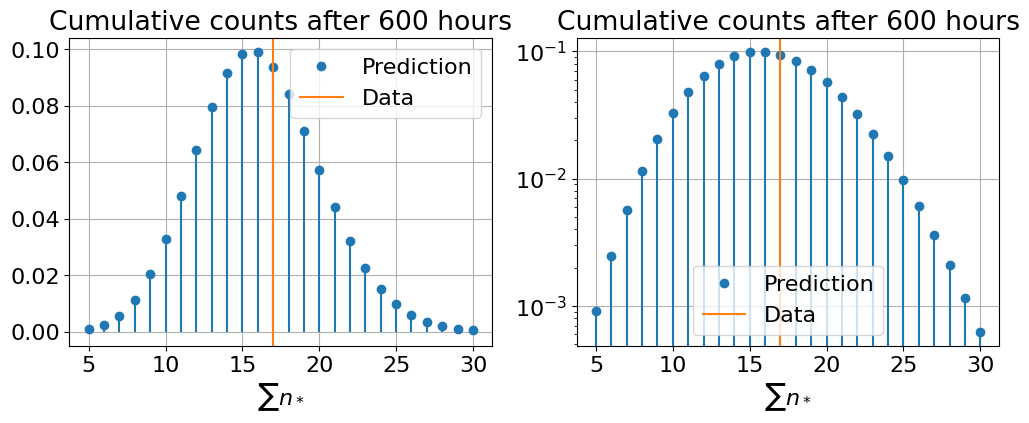

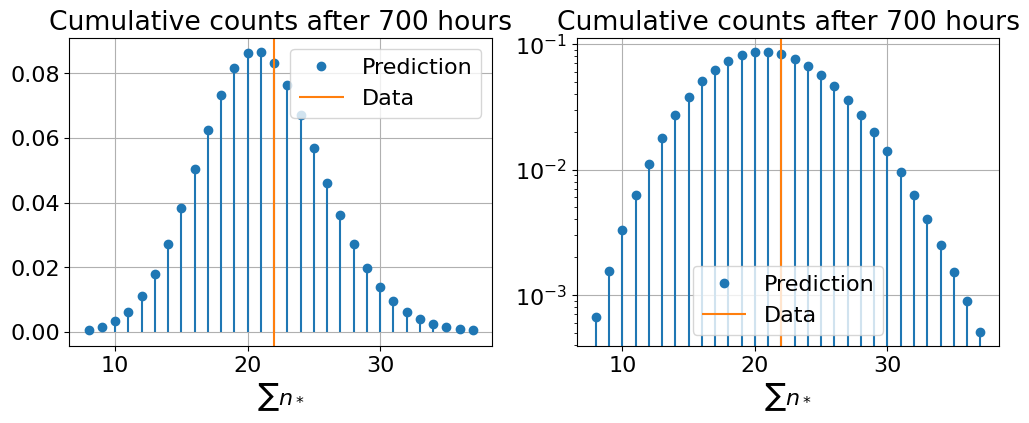

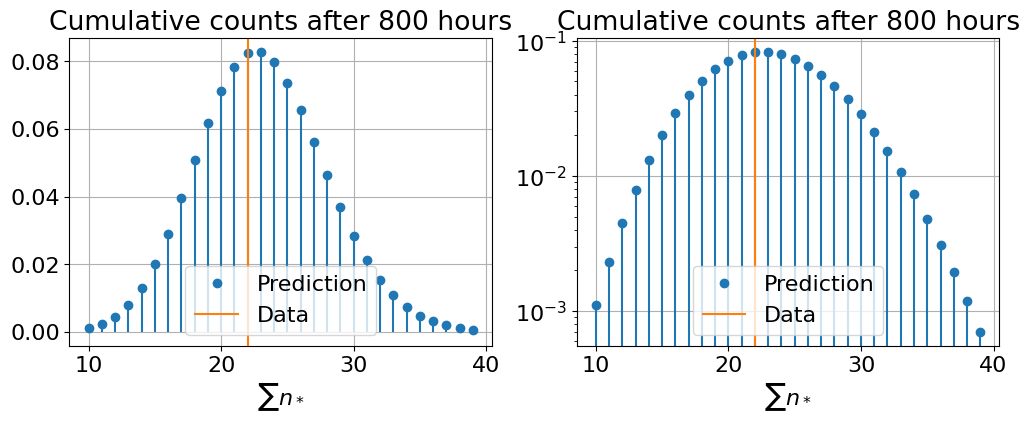

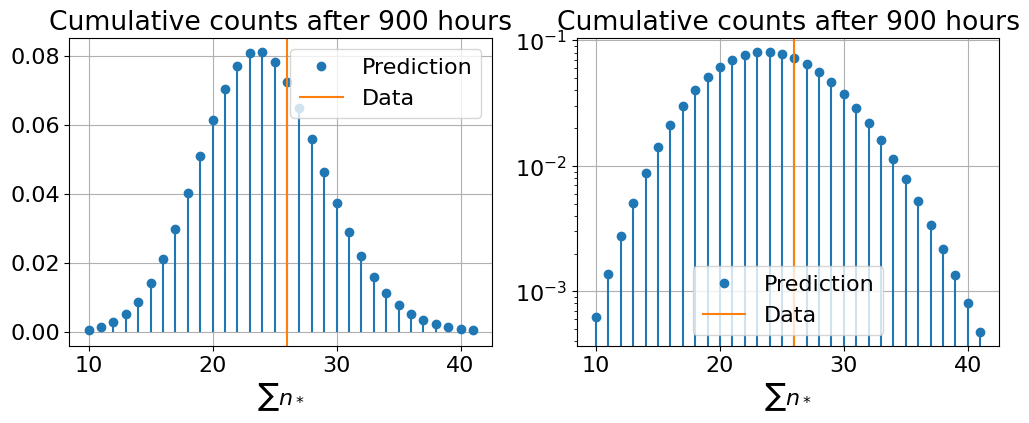

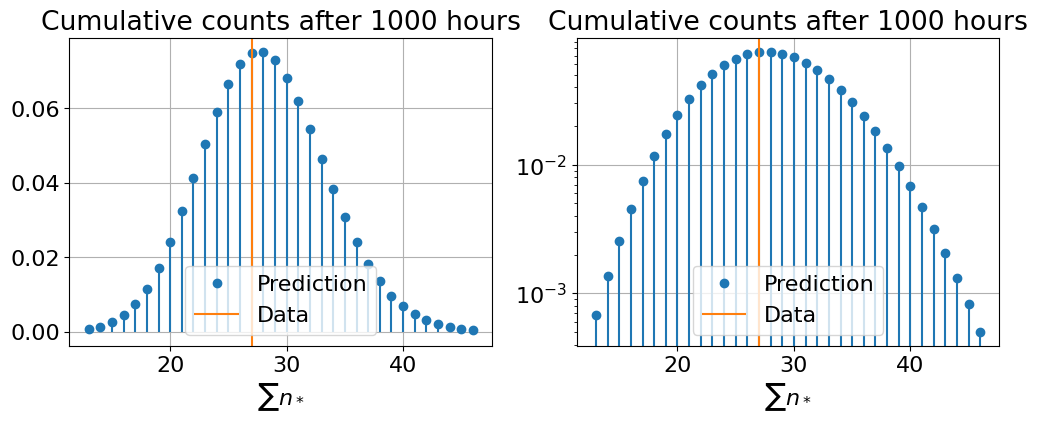

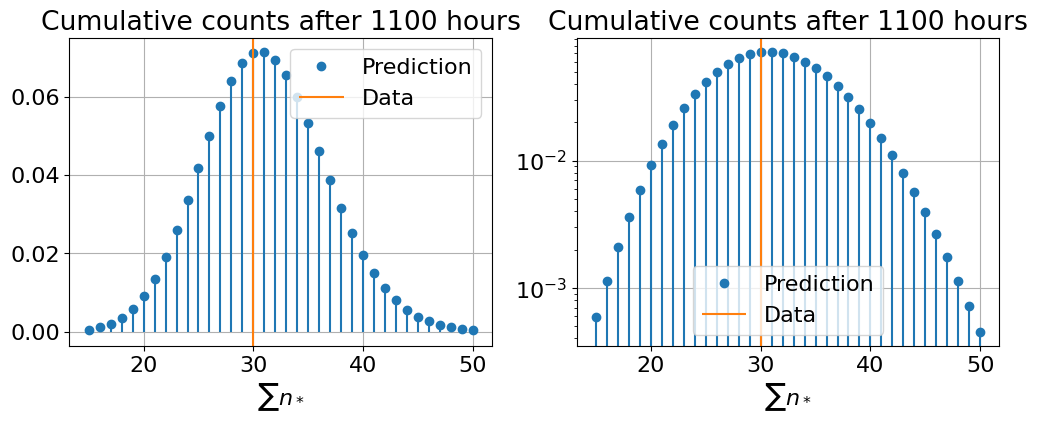

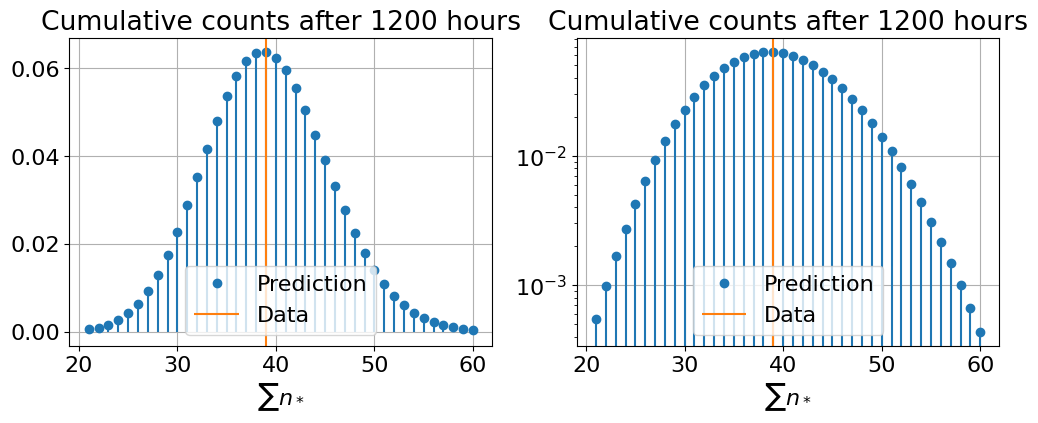

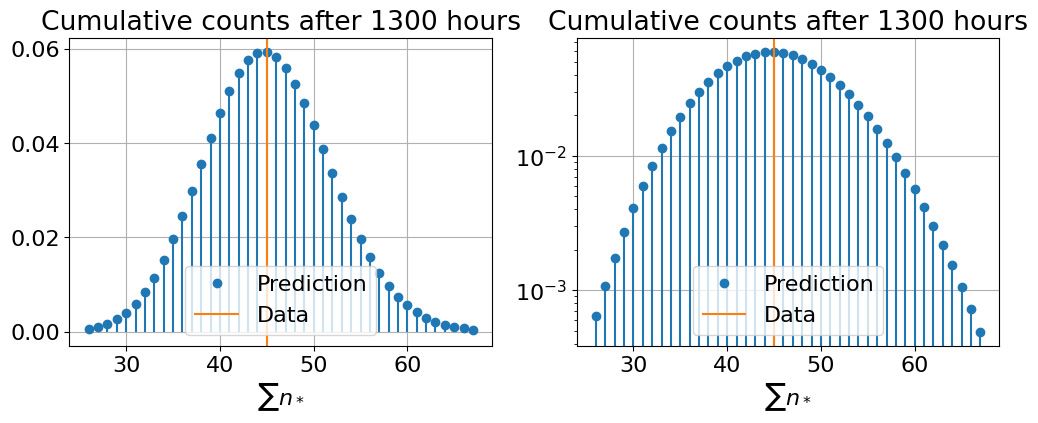

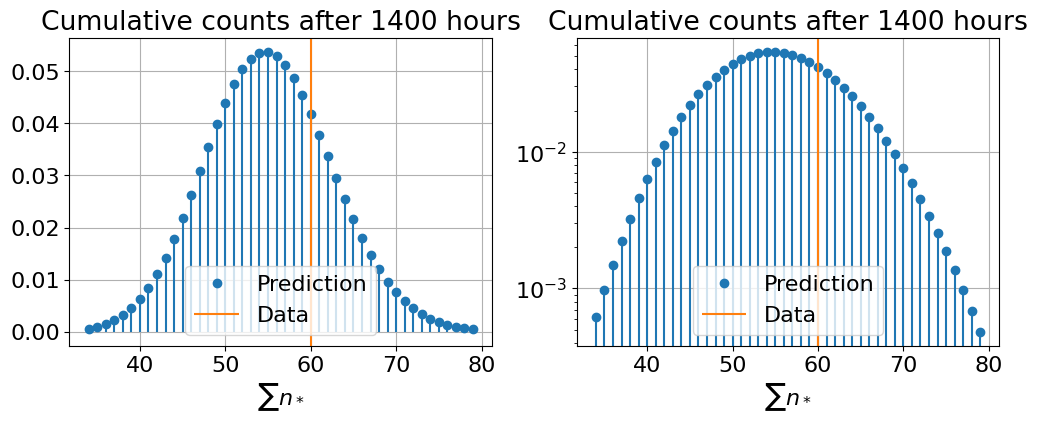

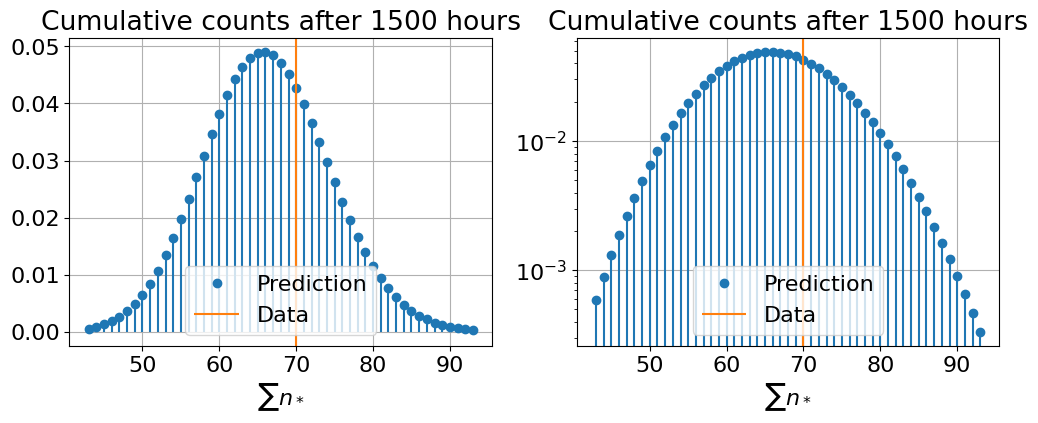

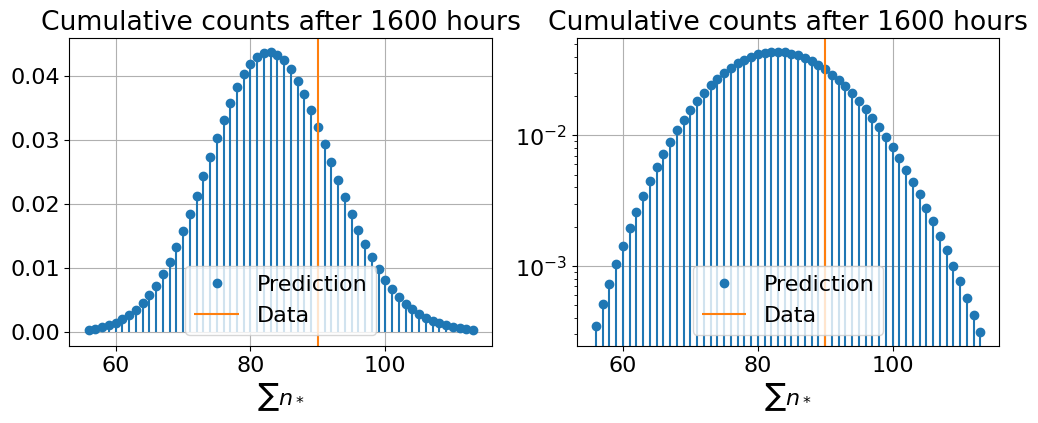

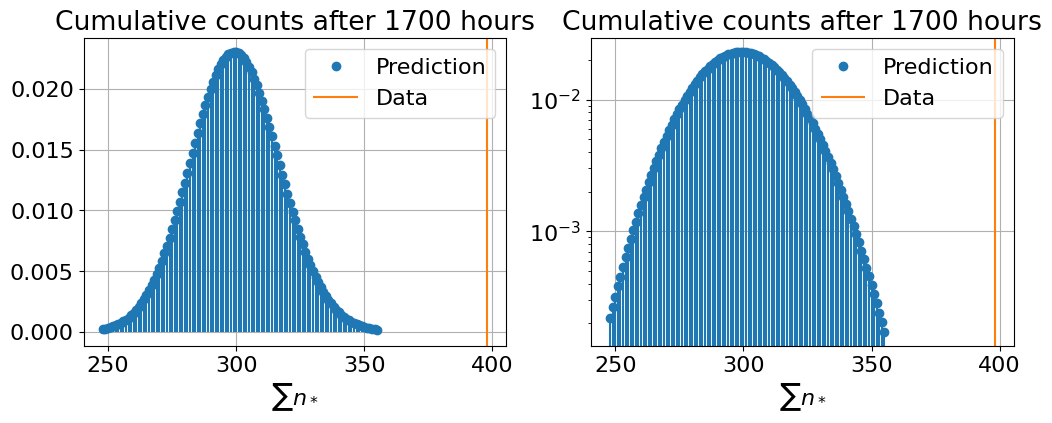

In [ ]:
# Distribution of the predicted cumulative counts from the data 24 hours before
step = 100
for hrs in range(step, data.index.max(), step):
    param = data.loc[hrs-deltat]
    pred = nbinom(param["a"]*hrs, param["b"]/(1+param["b"]))
    nmin = pred.ppf(0.001)
    nmax = pred.ppf(0.999)
    n = np.arange(nmin, nmax+1, dtype=int)
    fig, ax = plt.subplots(1, 2, figsize=(12,4))
    for i in range(2):
        ax[i].vlines(n, 0, pred.pmf(n))
        ax[i].plot(n, pred.pmf(n), 'o', label="Prediction")
        if i == 1:
            ax[1].set_yscale("log")
        ylim = ax[i].get_ylim()
        ax[i].vlines(data["cnt"].loc[hrs], ylim[0], ylim[1], "C1", label="Data")
        ax[i].set_ylim(ylim)
        ax[i].grid()
        ax[i].set_title(f"Cumulative counts after {hrs} hours")
        ax[i].set_xlabel("$\sum n_*$")
        ax[i].legend()
    plt.show()